# CLAM-TR v19.3: Multi-Scale Prostate Cancer Grading (Fixed Structure)

This notebook implements a complete experimental pipeline for prostate cancer grading using:
- Multi-scale attention (L0 + L1 features)
- Decay attention mechanism with learnable gamma
- TopK tile selection for efficiency
- CORAL ordinal regression

**Cell Structure**: 64 numbered code cells (0.1-9.3) organized in 10 parts.

---
# PART 0: SETUP & VERIFICATION

In [2]:
"""
Cell 0.1: Imports
"""
import os
import sys
import glob
import json
import time
import random
import shutil
import hashlib
import warnings
from datetime import datetime
from collections import defaultdict, Counter
from typing import Dict, List, Optional, Tuple, Any, Union

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)
from scipy import stats
from scipy.spatial import cKDTree

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm

# Mount Google Drive first
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
        print("Google Drive mounted successfully!")
        time.sleep(2)  # Wait for sync
    else:
        print("Google Drive already mounted.")
except ImportError:
    print("Not running in Colab - skipping Drive mount")

warnings.filterwarnings("ignore")

print("=" * 70)
print("CLAM-TR v19.3: Multi-Scale Prostate Cancer Grading")
print("=" * 70)
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("=" * 70)


Mounted at /content/drive
Google Drive mounted successfully!
CLAM-TR v19.3: Multi-Scale Prostate Cancer Grading
Python: 3.12.12
PyTorch: 2.9.0+cu126
NumPy: 2.0.2
Pandas: 2.2.2
CUDA available: True
CUDA device: Tesla T4
CUDA memory: 15.8 GB


In [3]:
"""
Cell 0.2: Configuration - V19 Multi-Scale Experiments
"""
RESET_RESULTS_DIR = False

CONFIG = {
    # === FEATURE PATHS ===
    "features_l0_dir": "/content/drive/MyDrive/CLAM_TR_Features/uni/",
    "features_l1_dir": "/content/drive/MyDrive/CLAM_TR_Features/L1_P2_provider/uni/",
    "checkpoints_dir": "/content/drive/MyDrive/CLAM_TR_Checkpoints/",
    "results_dir": "/content/drive/MyDrive/CLAM_TR_Results/v19_multiscale/",

    # Feature dimensions
    "feature_dim_l0": 1024,
    "feature_dim_l1": 1024,

    # Model architecture
    "hidden_dim": 512,
    "num_heads": 4,
    "gamma_values": [0.8, 0.9, 0.95, 0.99],
    "dropout": 0.15,

    # Training
    "epochs": 50,
    "early_stopping_patience": 10,
    "weight_decay": 1e-5,

    # Gradient clipping
    "max_grad_norm": 1.0,

    # Cross-validation
    "n_folds": 5,
    "seed": 42,

    # Memory
    "cdist_max_elements": 50_000_000,
    "cache_version": "v19_cache_v1",
}

# Learning rates
LR_SWEEP = [1e-4, 5e-5]

# TopK values
TOPK_VALUES_L1 = [32, 64]
TOPK_VALUES_L0 = [64, 128, 256]
TOPK_VALUES_MS = [64, 128]
TOPK_VALUES = TOPK_VALUES_L0

# Hard grades
HARD_GRADES_ISUP = [2, 3, 4]

RESULTS_SUBDIRS = ["matching_cache", "figures", "folds", "logs", "checkpoints", "fold_predictions"]

print("=" * 70)
print("V19 CONFIGURATION")
print("=" * 70)
print(f"L0 features (5x):  {CONFIG['features_l0_dir']}")
print(f"L1 features (20x): {CONFIG['features_l1_dir']}")
print(f"Gamma values:      {CONFIG['gamma_values']}")
print("=" * 70)


V19 CONFIGURATION
L0 features (5x):  /content/drive/MyDrive/CLAM_TR_Features/uni/
L1 features (20x): /content/drive/MyDrive/CLAM_TR_Features/L1_P2_provider/uni/
Gamma values:      [0.8, 0.9, 0.95, 0.99]


In [4]:
"""
Cell 0.3: Reproducibility & Device
"""
def set_seed(seed: int = 42) -> None:
    """Set all random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE = device  # Global alias
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# Create directories
os.makedirs(CONFIG['results_dir'], exist_ok=True)
os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
for subdir in RESULTS_SUBDIRS:
    os.makedirs(os.path.join(CONFIG['results_dir'], subdir), exist_ok=True)
CACHE_DIR = os.path.join(CONFIG['results_dir'], CONFIG['cache_version'])
os.makedirs(CACHE_DIR, exist_ok=True)
print(f"\nCache directory: {CACHE_DIR}")

Device: cuda
  GPU: Tesla T4
  Memory: 15.8 GB

Cache directory: /content/drive/MyDrive/CLAM_TR_Results/v19_multiscale/v19_cache_v1


In [5]:
"""
Cell 0.4: Verify L0 Features (5x - Architecture)
With better debugging for Google Drive sync issues.
"""
import time

l0_dir = CONFIG['features_l0_dir']
print(f"\nL0 features directory: {l0_dir}")

# Check if directory exists
if not os.path.exists(l0_dir):
    print(f"  ERROR: Directory does not exist!")
    print(f"  Checking parent directory...")
    parent = os.path.dirname(l0_dir.rstrip('/'))
    if os.path.exists(parent):
        print(f"  Parent exists: {parent}")
        print(f"  Contents: {os.listdir(parent)[:10]}...")
    raise FileNotFoundError(f"Directory not found: {l0_dir}")

# List directory contents directly first
print(f"  Directory exists: True")
try:
    all_files = os.listdir(l0_dir)
    pt_files_direct = [f for f in all_files if f.endswith('.pt')]
    print(f"  Files in directory (os.listdir): {len(all_files)}")
    print(f"  .pt files (os.listdir): {len(pt_files_direct)}")
    if pt_files_direct:
        print(f"  Sample files: {pt_files_direct[:3]}")
except Exception as e:
    print(f"  ERROR listing directory: {e}")

# Now try glob
l0_files = glob.glob(os.path.join(l0_dir, '*.pt'))
print(f"  .pt files (glob): {len(l0_files)}")

# If glob fails but listdir works, use listdir
if len(l0_files) == 0 and len(pt_files_direct) > 0:
    print("  Using os.listdir instead of glob...")
    l0_files = [os.path.join(l0_dir, f) for f in pt_files_direct]

if not l0_files:
    print("\n" + "="*60)
    print("ERROR: No .pt files found!")
    print("Please verify the path contains feature files.")
    print("="*60)
    raise FileNotFoundError(f"No L0 feature files found in {l0_dir}")

print(f"\nL0 feature files: {len(l0_files)}")

# Detect keys
sample_data = torch.load(l0_files[0], map_location='cpu', weights_only=False)
CONFIG['feat_key_l0'] = 'features' if 'features' in sample_data else 'feats'
CONFIG['coord_key_l0'] = 'coordinates' if 'coordinates' in sample_data else ('coords' if 'coords' in sample_data else None)

print(f"  Keys: {list(sample_data.keys())}")
print(f"  feat_key_l0: '{CONFIG['feat_key_l0']}'")
print(f"  coord_key_l0: '{CONFIG['coord_key_l0']}'")
print(f"  Feature shape: {sample_data[CONFIG['feat_key_l0']].shape}")

# Sample statistics
sample_sizes = [torch.load(f, map_location='cpu', weights_only=False)[CONFIG['feat_key_l0']].shape[0] for f in l0_files[:20]]
print(f"  Avg patches (L0): {np.mean(sample_sizes):.1f}")

# Store L0 slide IDs
L0_SLIDE_IDS = set(os.path.basename(f).replace('.pt', '') for f in l0_files)
print(f"  Total L0 slides: {len(L0_SLIDE_IDS)}")


L0 features directory: /content/drive/MyDrive/CLAM_TR_Features/uni/
  Directory exists: True
  Files in directory (os.listdir): 600
  .pt files (os.listdir): 600
  Sample files: ['6b69560eba8205a182f996d752402036.pt', '14820c513b48eaf1025e6d876ea87d52.pt', 'c95bfd7e7fcb784d245163e8305143cc.pt']
  .pt files (glob): 600

L0 feature files: 600
  Keys: ['features', 'coordinates']
  feat_key_l0: 'features'
  coord_key_l0: 'coordinates'
  Feature shape: torch.Size([355, 1024])
  Avg patches (L0): 437.8
  Total L0 slides: 600


In [6]:
"""
Cell 0.5: Verify L1 Features (20x - Cytology)
Expected ~77 patches/slide.
"""
l1_dir = CONFIG['features_l1_dir']
l1_files = glob.glob(os.path.join(l1_dir, '*.pt'))
print(f"L1 features directory: {l1_dir}")
print(f"L1 feature files: {len(l1_files)}")

L1_AVAILABLE = len(l1_files) > 0

if l1_files:
    # Detect keys
    sample_data = torch.load(l1_files[0], map_location='cpu', weights_only=False)
    CONFIG['feat_key_l1'] = 'features' if 'features' in sample_data else 'feats'
    CONFIG['coord_key_l1'] = 'coordinates' if 'coordinates' in sample_data else ('coords' if 'coords' in sample_data else None)

    print(f"  Keys: {list(sample_data.keys())}")
    print(f"  feat_key_l1: '{CONFIG['feat_key_l1']}'")
    print(f"  coord_key_l1: '{CONFIG['coord_key_l1']}'")
    print(f"  Feature shape: {sample_data[CONFIG['feat_key_l1']].shape}")

    # Sample statistics
    sample_sizes = [torch.load(f, map_location='cpu', weights_only=False)[CONFIG['feat_key_l1']].shape[0] for f in l1_files[:20]]
    print(f"  Avg patches (L1): {np.mean(sample_sizes):.1f} (expected ~77)")

    # Verify file count matches
    L1_SLIDE_IDS = set(os.path.basename(f).replace('.pt', '') for f in l1_files)
    COMMON_SLIDE_IDS = L0_SLIDE_IDS & L1_SLIDE_IDS
    print(f"\nFile overlap: {len(COMMON_SLIDE_IDS)} slides have both L0 and L1 features")
else:
    print("\n" + "="*60)
    print("WARNING: No L1 feature files found!")
    print("Multi-scale experiments will be DISABLED")
    print("Running single-scale (L0 only) experiments")
    print("="*60)
    CONFIG['feat_key_l1'] = CONFIG['feat_key_l0']
    CONFIG['coord_key_l1'] = CONFIG['coord_key_l0']
    L1_SLIDE_IDS = set()
    COMMON_SLIDE_IDS = set()

L1 features directory: /content/drive/MyDrive/CLAM_TR_Features/L1_P2_provider/uni/
L1 feature files: 600
  Keys: ['features', 'coordinates', 'config', 'encoder']
  feat_key_l1: 'features'
  coord_key_l1: 'coordinates'
  Feature shape: torch.Size([77, 1024])
  Avg patches (L1): 46.5 (expected ~77)

File overlap: 600 slides have both L0 and L1 features


Slide 0704a3d9:
  L0: 303 patches, bbox X=[7680, 12544]
  L1: 60 patches, bbox X=[1920, 3072]
Slide 03db76b0:
  L0: 268 patches, bbox X=[1280, 10752]
  L1: 61 patches, bbox X=[384, 2688]
Slide 117e082d:
  L0: 404 patches, bbox X=[14336, 27136]
  L1: 79 patches, bbox X=[3648, 6720]


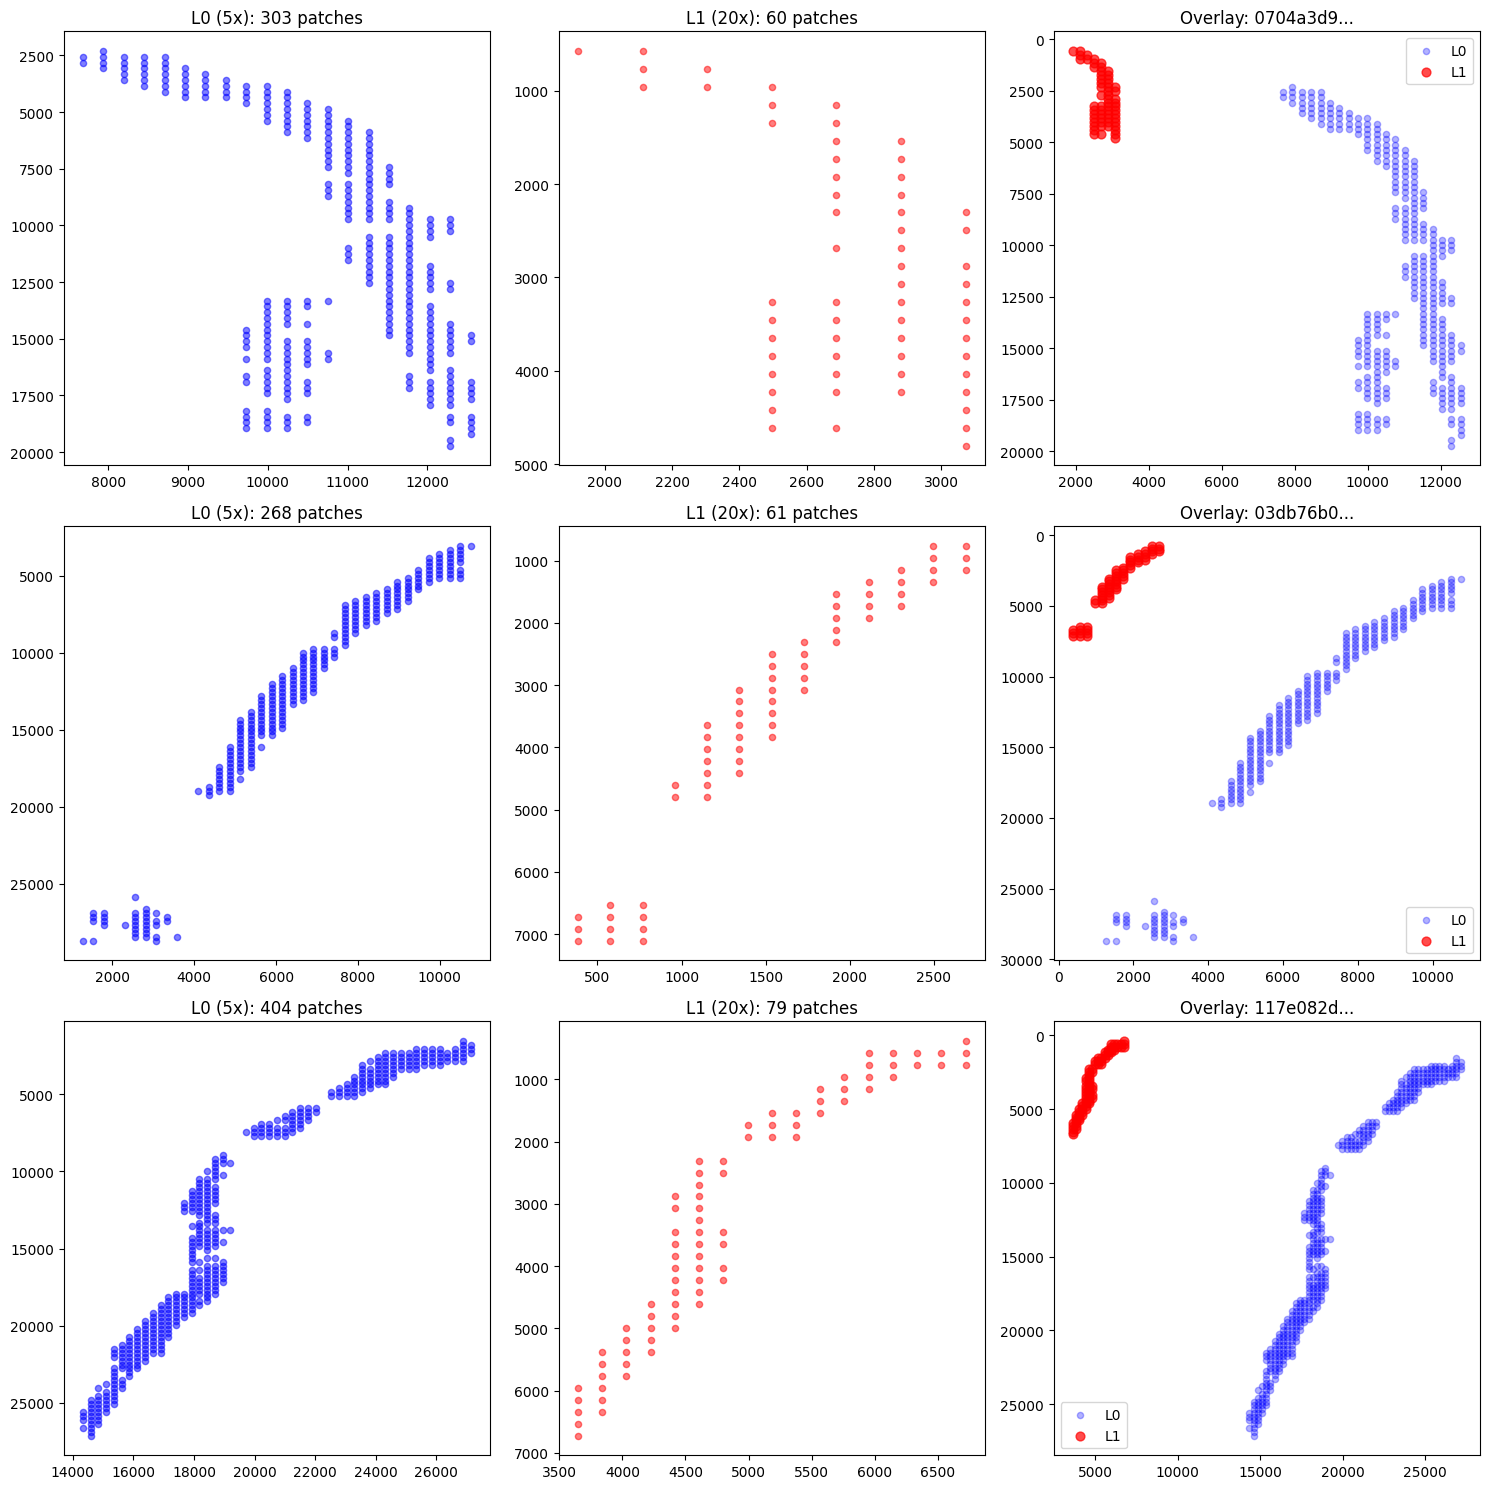


Coordinate verification complete.
Review the plots above to confirm L0 and L1 are spatially aligned.
If aligned: Multi-scale experiments ENABLED


In [7]:
"""
Cell 0.6: Coordinate System Verification
CRITICAL: Verify L0 and L1 coordinates are in the same space before multi-scale.
"""
import matplotlib.pyplot as plt

MULTISCALE_ENABLED = False

if L1_AVAILABLE and len(COMMON_SLIDE_IDS) > 0:
    # Sample 3 slides for verification
    sample_ids = list(COMMON_SLIDE_IDS)[:3]

    coord_systems_compatible = True
    fig, axes = plt.subplots(len(sample_ids), 3, figsize=(15, 5*len(sample_ids)))
    if len(sample_ids) == 1:
        axes = axes.reshape(1, -1)

    for i, sample_id in enumerate(sample_ids):
        l0_path = os.path.join(CONFIG['features_l0_dir'], f"{sample_id}.pt")
        l1_path = os.path.join(CONFIG['features_l1_dir'], f"{sample_id}.pt")

        l0_data = torch.load(l0_path, map_location='cpu', weights_only=False)
        l1_data = torch.load(l1_path, map_location='cpu', weights_only=False)

        coords_l0 = l0_data[CONFIG['coord_key_l0']].numpy() if CONFIG['coord_key_l0'] else np.zeros((1,2))
        coords_l1 = l1_data[CONFIG['coord_key_l1']].numpy() if CONFIG['coord_key_l1'] else np.zeros((1,2))

        # Plot L0
        axes[i, 0].scatter(coords_l0[:,0], coords_l0[:,1], alpha=0.5, s=20, c='blue')
        axes[i, 0].set_title(f'L0 (5x): {len(coords_l0)} patches')
        axes[i, 0].invert_yaxis()

        # Plot L1
        axes[i, 1].scatter(coords_l1[:,0], coords_l1[:,1], alpha=0.5, s=20, c='red')
        axes[i, 1].set_title(f'L1 (20x): {len(coords_l1)} patches')
        axes[i, 1].invert_yaxis()

        # Overlay
        axes[i, 2].scatter(coords_l0[:,0], coords_l0[:,1], alpha=0.3, s=20, c='blue', label='L0')
        axes[i, 2].scatter(coords_l1[:,0], coords_l1[:,1], alpha=0.7, s=40, c='red', label='L1')
        axes[i, 2].set_title(f'Overlay: {sample_id[:8]}...')
        axes[i, 2].legend()
        axes[i, 2].invert_yaxis()

        # Check bounding box overlap
        l0_bbox = [coords_l0[:,0].min(), coords_l0[:,0].max(), coords_l0[:,1].min(), coords_l0[:,1].max()]
        l1_bbox = [coords_l1[:,0].min(), coords_l1[:,0].max(), coords_l1[:,1].min(), coords_l1[:,1].max()]

        print(f"Slide {sample_id[:8]}:")
        print(f"  L0: {len(coords_l0)} patches, bbox X=[{l0_bbox[0]:.0f}, {l0_bbox[1]:.0f}]")
        print(f"  L1: {len(coords_l1)} patches, bbox X=[{l1_bbox[0]:.0f}, {l1_bbox[1]:.0f}]")

    plt.tight_layout()
    save_path = os.path.join(CONFIG['results_dir'], 'figures', 'coord_verification.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=150)
    plt.show()

    MULTISCALE_ENABLED = True
    print("\n" + "="*60)
    print("Coordinate verification complete.")
    print("Review the plots above to confirm L0 and L1 are spatially aligned.")
    print("If aligned: Multi-scale experiments ENABLED")
    print("="*60)
else:
    print("Skipping coordinate verification - L1 features not available")
    print("Multi-scale experiments DISABLED")

In [8]:
"""
Cell 0.7: Load CSV and Filter to Available Features
"""
from sklearn.model_selection import StratifiedKFold

# Find CSV
csv_candidates = [
    '/content/drive/MyDrive/CLAM_TR_Checkpoints/subset_600.csv',
    '/content/drive/MyDrive/subset_600.csv',
    '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train.csv',
]

df = None
for csv_path in csv_candidates:
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        print(f"Loaded CSV: {csv_path} ({len(df)} rows)")
        break

if df is None:
    raise FileNotFoundError("No CSV found!")

# Rename kfold to fold if needed
if 'kfold' in df.columns:
    df = df.rename(columns={'kfold': 'fold'})

# Filter to slides with L0 features
df = df[df['image_id'].isin(L0_SLIDE_IDS)].copy()
print(f"Slides with L0 features: {len(df)}")

# Create fold assignments if missing
if 'fold' not in df.columns:
    print("Creating stratified 5-fold assignments...")
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=CONFIG['seed'])
    df['fold'] = -1
    for fold, (_, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        df.loc[df.index[val_idx], 'fold'] = fold

print(f"\nGrade distribution:")
print(df['isup_grade'].value_counts().sort_index())

# Create df_6class for 6-class experiments (grades 0-5)
df_6class = df.copy()
print(f"df_6class ready: {len(df_6class)} slides for 6-class experiments")

# Create df_5class for 5-class experiments (grades 1-5, excluding grade 0)
df_5class = df[df['isup_grade'] > 0].copy()
df_5class['label'] = df_5class['isup_grade'] - 1  # Map grades 1-5 to labels 0-4
print(f"df_5class ready: {len(df_5class)} slides for 5-class experiments (grades 1-5)")


Loaded CSV: /content/drive/MyDrive/CLAM_TR_Checkpoints/subset_600.csv (600 rows)
Slides with L0 features: 600
Creating stratified 5-fold assignments...

Grade distribution:
isup_grade
0    100
1    100
2    100
3    100
4    100
5    100
Name: count, dtype: int64
df_6class ready: 600 slides for 6-class experiments
df_5class ready: 500 slides for 5-class experiments (grades 1-5)


In [9]:
"""
================================================================================
EXPERIMENT: V18 REPRODUCTION (6-class)
================================================================================
EXACT V18 CODE - Copied directly from V18 notebook.
Uses normalize_coordinates() with torch.clamp(coords_range, min=1.0)
================================================================================
"""
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import cohen_kappa_score, accuracy_score

# ============================================================================
# V18_CONFIG (SEPARATE - does NOT overwrite V19 CONFIG)
# ============================================================================
V18_CONFIG = {
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/uni/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v18_reproduction/',
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'num_heads': 4,
    'gamma_values': [0.8, 0.9, 0.95, 0.99],
    'top_k': 128,
    'dropout': 0.15,
    'lr': 1e-4,
    'weight_decay': 1e-5,
    'epochs': 50,
    'early_stopping_patience': 10,
    'n_folds': 5,
    'seed': 42,
}

V18_REFERENCE = {"qwk": 0.8741, "accuracy": 0.6417}

random.seed(V18_CONFIG['seed'])
np.random.seed(V18_CONFIG['seed'])
torch.manual_seed(V18_CONFIG['seed'])
torch.cuda.manual_seed_all(V18_CONFIG['seed'])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
os.makedirs(V18_CONFIG['results_dir'], exist_ok=True)
print(f'Results will be saved to: {V18_CONFIG["results_dir"]}')


# ============================================================================
# EXACT V18: normalize_coordinates (with torch.clamp)
# ============================================================================
def normalize_coordinates(coords, method='minmax'):
    """Normalize patch coordinates - EXACT V18 CODE."""
    coords_float = coords.float()

    if method == 'minmax':
        coords_min = coords_float.min(dim=0, keepdim=True).values
        coords_max = coords_float.max(dim=0, keepdim=True).values
        coords_range = coords_max - coords_min
        coords_range = torch.clamp(coords_range, min=1.0)  # V18: clamp, not +1e-8
        coords_norm = (coords_float - coords_min) / coords_range
    elif method == 'standard':
        coords_mean = coords_float.mean(dim=0, keepdim=True)
        coords_std = coords_float.std(dim=0, keepdim=True)
        coords_std = torch.clamp(coords_std, min=1e-8)
        coords_norm = (coords_float - coords_mean) / coords_std
    else:
        coords_norm = coords_float

    return coords_norm


# ============================================================================
# EXACT V18: FocalLoss
# ============================================================================
class FocalLoss_V18(nn.Module):
    def __init__(self, gamma=1.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)
        ce = F.cross_entropy(logits, target, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


# ============================================================================
# EXACT V18: SpatialRetentionHead_FIXED
# ============================================================================
class SpatialRetentionHead_FIXED(nn.Module):
    """EXACT V18 Implementation: Additive decay bias BEFORE softmax."""

    def __init__(self, hidden_dim=512, num_heads=4, gamma_values=None,
                 decay_type='exponential', sigma_values=None,
                 coord_normalize='minmax', dropout=0.15):
        super().__init__()

        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.head_dim = hidden_dim // num_heads
        self.coord_normalize = coord_normalize
        self.decay_type = decay_type

        # Exponential decay: gamma values (FIXED via register_buffer)
        if gamma_values is None:
            gamma_values = [0.8, 0.9, 0.95, 0.99]
        gamma_values = gamma_values[:num_heads] if len(gamma_values) >= num_heads else \
                      gamma_values + [0.95] * (num_heads - len(gamma_values))
        self.register_buffer('gamma', torch.tensor(gamma_values, dtype=torch.float32))

        # Gaussian decay: sigma values
        if sigma_values is None:
            sigma_values = [0.1, 0.2, 0.5, 1.0]
        sigma_values = sigma_values[:num_heads] if len(sigma_values) >= num_heads else \
                      sigma_values + [0.5] * (num_heads - len(sigma_values))
        self.register_buffer('sigma', torch.tensor(sigma_values, dtype=torch.float32))

        self.W_Q = nn.Linear(hidden_dim, hidden_dim)
        self.W_K = nn.Linear(hidden_dim, hidden_dim)
        self.W_V = nn.Linear(hidden_dim, hidden_dim)
        self.W_O = nn.Linear(hidden_dim, hidden_dim)

        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, coords):
        N = x.size(0)
        dtype = x.dtype
        H, D = self.num_heads, self.head_dim

        # Compute pairwise distances (EXACT V18: uses normalize_coordinates)
        with torch.no_grad():
            coords_norm = normalize_coordinates(coords, self.coord_normalize).float()
            dist = torch.cdist(coords_norm, coords_norm)

        # Compute spatial bias based on decay type
        if self.decay_type == 'exponential':
            gamma = self.gamma.view(H, 1, 1)
            bias = dist.unsqueeze(0) * torch.log(gamma + 1e-8)
        else:  # Gaussian
            sigma = self.sigma.view(H, 1, 1)
            bias = -(dist.unsqueeze(0) ** 2) / (2 * sigma ** 2 + 1e-8)

        bias = bias.to(dtype)

        # QKV projections
        Q = self.W_Q(x).view(N, H, D).transpose(0, 1)
        K = self.W_K(x).view(N, H, D).transpose(0, 1)
        V = self.W_V(x).view(N, H, D).transpose(0, 1)

        # Attention with additive spatial bias
        scale = D ** 0.5
        logits = torch.bmm(Q, K.transpose(1, 2)) / scale
        attn = torch.softmax(logits + bias, dim=-1)
        attn = self.dropout(attn)

        # Aggregate
        out = torch.bmm(attn, V)
        out = out.transpose(0, 1).contiguous().view(N, self.hidden_dim)
        out = self.W_O(out)
        out = self.norm(x + out)

        slide_repr = out.mean(dim=0)
        return slide_repr, None


# ============================================================================
# EXACT V18: TopKRetention
# ============================================================================
class TopKRetention_V18(nn.Module):
    """EXACT V18: Two-stage Top-K Retention with ABMIL + Retention fusion."""

    def __init__(self, feature_dim=1024, hidden_dim=512, n_classes=6,
                 num_heads=4, gamma_values=None, top_k=128, dropout=0.15):
        super().__init__()
        self.top_k = top_k
        self.hidden_dim = hidden_dim

        self.feature_transform = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.tile_attention = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        self.retention = SpatialRetentionHead_FIXED(
            hidden_dim=hidden_dim,
            num_heads=num_heads,
            gamma_values=gamma_values or [0.8, 0.9, 0.95, 0.99],
            dropout=dropout
        )

        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, n_classes)
        )

    def forward(self, features, coords):
        N = features.size(0)
        h = self.feature_transform(features)

        a_logits = self.tile_attention(h)
        a = torch.softmax(a_logits, dim=0)
        M_abmil = torch.sum(a * h, dim=0)

        k = min(self.top_k, N)
        topk_idx = torch.topk(a.squeeze(-1), k, dim=0).indices
        h_selected = h[topk_idx]
        coords_selected = coords[topk_idx]
        M_ret, _ = self.retention(h_selected, coords_selected)

        M = self.fusion(torch.cat([M_abmil, M_ret], dim=-1))
        logits = self.classifier(M)

        return logits, a


# ============================================================================
# V18 Dataset
# ============================================================================
class V18Dataset(Dataset):
    def __init__(self, df, feature_dir):
        self.feature_dir = feature_dir
        # Filter to only slides with existing feature files
        valid_rows = []
        for idx, row in df.iterrows():
            feature_path = os.path.join(feature_dir, f"{row['image_id']}.pt")
            if os.path.exists(feature_path):
                valid_rows.append(row)
            else:
                print(f"  [SKIP] Missing: {row['image_id']}")
        self.df = pd.DataFrame(valid_rows).reset_index(drop=True)
        if len(self.df) < len(df):
            print(f"  Filtered: {len(df)} -> {len(self.df)} slides with features")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_id = row['image_id']
        label = int(row['isup_grade'])

        feature_path = os.path.join(self.feature_dir, f"{image_id}.pt")
        data = torch.load(feature_path, map_location='cpu', weights_only=False)

        features = data.get('features', data.get('feats', None))
        if features is None:
            for k, v in data.items():
                if isinstance(v, torch.Tensor) and v.dim() == 2:
                    features = v
                    break

        coords = data.get('coords', None)
        if coords is None:
            n = features.shape[0]
            side = int(np.ceil(np.sqrt(n)))
            x = torch.arange(n) % side
            y = torch.arange(n) // side
            coords = torch.stack([x, y], dim=1).float()

        return features, coords.float(), label, image_id


# ============================================================================
# RUN V18 REPRODUCTION
# ============================================================================
print("=" * 70)
print("V18 REPRODUCTION EXPERIMENT (EXACT V18 CODE)")
print("=" * 70)
print(f"Features: {V18_CONFIG['features_dir']}")
print(f"Model: TopKRetention_V18")
print(f"Gamma: {V18_CONFIG['gamma_values']} (FIXED)")
print(f"TopK: {V18_CONFIG['top_k']}")
print(f"Coord normalize: minmax with torch.clamp(min=1.0)")
print(f"Target QWK: {V18_REFERENCE['qwk']}")
print("=" * 70)

# Load CSV
csv_path = os.path.join(V18_CONFIG['checkpoints_dir'], 'subset_600.csv')
if not os.path.exists(csv_path):
    csv_path = '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train.csv'
df_v18 = pd.read_csv(csv_path)
print(f"Loaded CSV: {csv_path} ({len(df_v18)} rows)")

# Filter to available slides
available = set(f.replace('.pt', '') for f in os.listdir(V18_CONFIG['features_dir']) if f.endswith('.pt'))
df_v18 = df_v18[df_v18['image_id'].isin(available)].copy()
print(f"Slides with features: {len(df_v18)}")
print(f"Grade distribution:\n{df_v18['isup_grade'].value_counts().sort_index()}")

# 5-fold CV
skf = StratifiedKFold(n_splits=V18_CONFIG['n_folds'], shuffle=True, random_state=V18_CONFIG['seed'])

all_qwks = []
all_accs = []

for fold, (train_idx, val_idx) in enumerate(skf.split(df_v18['image_id'], df_v18['isup_grade'])):
    print(f"\n{'='*60}")
    print(f"FOLD {fold + 1}/{V18_CONFIG['n_folds']}")
    print(f"{'='*60}")

    # Check if this fold already completed (checkpoint exists)
    checkpoint_path = os.path.join(V18_CONFIG['checkpoints_dir'], f'v18_reproduction_fold{fold+1}_best.pt')
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
        saved_qwk = checkpoint.get('best_qwk', 0)
        saved_acc = checkpoint.get('best_acc', 0)
        print(f"  [RESUME] Found checkpoint: QWK={saved_qwk:.4f}, Acc={saved_acc:.4f}")
        all_qwks.append(saved_qwk)
        all_accs.append(saved_acc)
        print(f"  Skipping fold {fold+1} (already completed)")
        continue

    train_df = df_v18.iloc[train_idx]
    val_df = df_v18.iloc[val_idx]
    print(f"Train: {len(train_df)}, Val: {len(val_df)}")

    train_dataset = V18Dataset(train_df, V18_CONFIG['features_dir'])
    val_dataset = V18Dataset(val_df, V18_CONFIG['features_dir'])

    model = TopKRetention_V18(
        feature_dim=V18_CONFIG['feature_dim'],
        hidden_dim=V18_CONFIG['hidden_dim'],
        n_classes=V18_CONFIG['n_classes'],
        num_heads=V18_CONFIG['num_heads'],
        gamma_values=V18_CONFIG['gamma_values'],
        top_k=V18_CONFIG['top_k'],
        dropout=V18_CONFIG['dropout']
    ).to(DEVICE)

    criterion = FocalLoss_V18(gamma=1.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=V18_CONFIG['lr'], weight_decay=V18_CONFIG['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=V18_CONFIG['epochs'])

    best_qwk = 0
    best_acc = 0
    patience_counter = 0

    for epoch in range(V18_CONFIG['epochs']):
        model.train()
        train_loss = 0
        indices = list(range(len(train_dataset)))
        random.shuffle(indices)

        for i in indices:
            features, coords, label, _ = train_dataset[i]
            features = features.to(DEVICE)
            coords = coords.to(DEVICE)
            label_t = torch.tensor([label], dtype=torch.long, device=DEVICE)

            optimizer.zero_grad()
            logits, _ = model(features, coords)
            loss = criterion(logits.unsqueeze(0), label_t)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item()

        scheduler.step()

        model.eval()
        preds, labels_list = [], []

        with torch.no_grad():
            for i in range(len(val_dataset)):
                features, coords, label, _ = val_dataset[i]
                features = features.to(DEVICE)
                coords = coords.to(DEVICE)

                logits, _ = model(features, coords)
                pred = logits.argmax().item()
                preds.append(pred)
                labels_list.append(label)

        val_qwk = cohen_kappa_score(labels_list, preds, weights='quadratic')
        val_acc = accuracy_score(labels_list, preds)

        if val_qwk > best_qwk:
            best_qwk = val_qwk
            best_acc = val_acc
            patience_counter = 0
            # Save best checkpoint for this fold
            checkpoint_path = os.path.join(V18_CONFIG['checkpoints_dir'], f'v18_reproduction_fold{fold+1}_best.pt')
            torch.save({
                'fold': fold + 1,
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'best_qwk': best_qwk,
                'best_acc': best_acc,
            }, checkpoint_path)
        else:
            patience_counter += 1

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}: Loss={train_loss/len(train_dataset):.4f}, QWK={val_qwk:.4f}, Acc={val_acc:.4f}")

        if patience_counter >= V18_CONFIG['early_stopping_patience']:
            print(f"Early stopping at epoch {epoch+1}")
            break

    print(f"Fold {fold+1} Best: QWK={best_qwk:.4f}, Acc={best_acc:.4f}")
    all_qwks.append(best_qwk)
    all_accs.append(best_acc)

print("\n" + "=" * 70)
print("V18 REPRODUCTION RESULTS")
print("=" * 70)
print(f"QWK:      {np.mean(all_qwks):.4f} +/- {np.std(all_qwks):.4f} (Target: {V18_REFERENCE['qwk']})")
print(f"Accuracy: {np.mean(all_accs):.4f} +/- {np.std(all_accs):.4f} (Target: {V18_REFERENCE['accuracy']})")
print("=" * 70)


Device: cuda
Results will be saved to: /content/drive/MyDrive/CLAM_TR_Results/v18_reproduction/
V18 REPRODUCTION EXPERIMENT (EXACT V18 CODE)
Features: /content/drive/MyDrive/CLAM_TR_Features/uni/
Model: TopKRetention_V18
Gamma: [0.8, 0.9, 0.95, 0.99] (FIXED)
TopK: 128
Coord normalize: minmax with torch.clamp(min=1.0)
Target QWK: 0.8741
Loaded CSV: /content/drive/MyDrive/CLAM_TR_Checkpoints/subset_600.csv (600 rows)
Slides with features: 600
Grade distribution:
isup_grade
0    100
1    100
2    100
3    100
4    100
5    100
Name: count, dtype: int64

FOLD 1/5
  [RESUME] Found checkpoint: QWK=0.8263, Acc=0.5583
  Skipping fold 1 (already completed)

FOLD 2/5
  [RESUME] Found checkpoint: QWK=0.8931, Acc=0.6500
  Skipping fold 2 (already completed)

FOLD 3/5
  [RESUME] Found checkpoint: QWK=0.8462, Acc=0.6333
  Skipping fold 3 (already completed)

FOLD 4/5
  [RESUME] Found checkpoint: QWK=0.9178, Acc=0.6000
  Skipping fold 4 (already completed)

FOLD 5/5
  [RESUME] Found checkpoint: QWK=0

In [10]:
"""
Cell 0.8b: Coordinate Matching with KDTree Optimization
Vectorized O(N log N) matching for L0<->L1 spatial correspondence.
"""
from scipy.spatial import cKDTree

def compute_l0_l1_matching(
    coords_l1: torch.Tensor,
    coords_l0: torch.Tensor,
    max_elements: int = 50_000_000
) -> torch.Tensor:
    """
    For each L1 tile, find the nearest L0 tile using KDTree.

    Args:
        coords_l1: (N, 2) L1 tile coordinates
        coords_l0: (M, 2) L0 tile coordinates
        max_elements: Max elements for chunked processing (unused with KDTree)

    Returns:
        nn_idx: (N,) indices into L0 for each L1 tile

    Complexity: O(N log M) with KDTree vs O(N*M) with cdist
    """
    # Convert to numpy for scipy
    l1_np = coords_l1.numpy() if isinstance(coords_l1, torch.Tensor) else coords_l1
    l0_np = coords_l0.numpy() if isinstance(coords_l0, torch.Tensor) else coords_l0

    # Build KDTree on L0 coordinates (larger set)
    tree = cKDTree(l0_np)

    # Query nearest L0 tile for each L1 tile
    _, nn_idx = tree.query(l1_np, k=1)

    return torch.tensor(nn_idx, dtype=torch.long)


def precompute_matching_cache(
    slide_ids: list,
    feature_dir_l0: str,
    feature_dir_l1: str,
    cache_dir: str,
    coord_key_l0: str,
    coord_key_l1: str,
    force_recompute: bool = False
) -> int:
    """
    Precompute and cache L0<->L1 matching indices for all slides.

    Returns:
        Number of slides processed
    """
    os.makedirs(cache_dir, exist_ok=True)
    n_computed = 0

    for slide_id in tqdm(slide_ids, desc="Precomputing matching cache"):
        cache_path = os.path.join(cache_dir, f"{slide_id}_matching.pt")

        if os.path.exists(cache_path) and not force_recompute:
            continue

        l0_path = os.path.join(feature_dir_l0, f"{slide_id}.pt")
        l1_path = os.path.join(feature_dir_l1, f"{slide_id}.pt")

        if not os.path.exists(l0_path) or not os.path.exists(l1_path):
            continue

        l0_data = torch.load(l0_path, map_location='cpu', weights_only=False)
        l1_data = torch.load(l1_path, map_location='cpu', weights_only=False)

        if coord_key_l0 not in l0_data or coord_key_l1 not in l1_data:
            continue

        nn_idx = compute_l0_l1_matching(
            l1_data[coord_key_l1],
            l0_data[coord_key_l0]
        )

        torch.save({"nn_idx": nn_idx}, cache_path)
        n_computed += 1

    return n_computed


print("Coordinate matching functions defined:")
print("  - compute_l0_l1_matching (KDTree-based, O(N log M))")
print("  - precompute_matching_cache")


Coordinate matching functions defined:
  - compute_l0_l1_matching (KDTree-based, O(N log M))
  - precompute_matching_cache


In [11]:
"""
Cell 0.9: Dataset Classes (BOTH SingleScale AND MultiScale)
"""
class SingleScaleSlideDataset(Dataset):
    """Dataset for single-scale (L1 only) slide classification."""

    def __init__(self, df: pd.DataFrame, feature_dir: str, label_col: str = 'label'):
        self.df = df.reset_index(drop=True)
        self.feature_dir = feature_dir
        self.label_col = label_col
        self.feat_key = CONFIG.get('feat_key_l1', 'features')
        self.coord_key = CONFIG.get('coord_key_l1', 'coords')

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, int, str, str]:
        row = self.df.iloc[idx]
        image_id = row['image_id']
        label = int(row[self.label_col])
        provider = row.get('data_provider', 'unknown')

        feature_path = os.path.join(self.feature_dir, f"{image_id}.pt")
        if not os.path.exists(feature_path):
            raise FileNotFoundError(f"Feature file not found: {feature_path}")

        data = torch.load(feature_path, map_location='cpu', weights_only=False)
        features = data[self.feat_key]

        if self.coord_key and self.coord_key in data:
            coords = data[self.coord_key].float()
        else:
            n_tiles = features.shape[0]
            side = int(np.ceil(np.sqrt(n_tiles)))
            x = torch.arange(n_tiles) % side
            y = torch.arange(n_tiles) // side
            coords = torch.stack([x, y], dim=1).float()

        return features, coords, label, image_id, provider


class MultiScaleSlideDataset(Dataset):
    """Dataset for multi-scale (L1 + L0) slide classification."""

    def __init__(
        self,
        df: pd.DataFrame,
        feature_dir_l1: str,
        feature_dir_l0: str,
        cache_dir: str,
        label_col: str = 'label',
        max_tiles: Optional[int] = None,
        preload_cache: bool = False
    ):
        self.df = df.reset_index(drop=True)
        self.feature_dir_l1 = feature_dir_l1
        self.feature_dir_l0 = feature_dir_l0
        self.cache_dir = cache_dir
        self.label_col = label_col
        self.max_tiles = max_tiles

        self.feat_key_l1 = CONFIG.get('feat_key_l1', 'features')
        self.coord_key_l1 = CONFIG.get('coord_key_l1', 'coords')
        self.feat_key_l0 = CONFIG.get('feat_key_l0', 'features')
        self.coord_key_l0 = CONFIG.get('coord_key_l0', 'coords')

        self.cache_dict = {}
        if preload_cache:
            print("Preloading matching cache...")
            for image_id in self.df['image_id'].unique():
                cache_path = os.path.join(cache_dir, f"{image_id}_matching.pt")
                if os.path.exists(cache_path):
                    self.cache_dict[image_id] = torch.load(cache_path, map_location='cpu', weights_only=False)

    def __len__(self) -> int:
        return len(self.df)

    def _load_cache(self, image_id: str) -> torch.Tensor:
        if image_id in self.cache_dict:
            return self.cache_dict[image_id]['nn_idx']
        cache_path = os.path.join(self.cache_dir, f"{image_id}_matching.pt")
        if os.path.exists(cache_path):
            cache_data = torch.load(cache_path, map_location='cpu', weights_only=False)
            return cache_data['nn_idx']
        return None

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, int, str, str]:
        row = self.df.iloc[idx]
        image_id = row['image_id']
        label = int(row[self.label_col])
        provider = row.get('data_provider', 'unknown')

        # Load L1 features
        l1_path = os.path.join(self.feature_dir_l1, f"{image_id}.pt")
        if not os.path.exists(l1_path):
            raise FileNotFoundError(f"L1 not found: {l1_path}")
        l1_data = torch.load(l1_path, map_location='cpu', weights_only=False)
        features_l1 = l1_data[self.feat_key_l1]

        # Get L1 coords
        if self.coord_key_l1 and self.coord_key_l1 in l1_data:
            coords_l1 = l1_data[self.coord_key_l1].float()
        else:
            n = features_l1.shape[0]
            side = int(np.ceil(np.sqrt(n)))
            coords_l1 = torch.stack([torch.arange(n) % side, torch.arange(n) // side], dim=1).float()

        # Load L0 features
        l0_path = os.path.join(self.feature_dir_l0, f"{image_id}.pt")
        if not os.path.exists(l0_path):
            raise FileNotFoundError(f"L0 not found: {l0_path}")
        l0_data = torch.load(l0_path, map_location='cpu', weights_only=False)
        features_l0 = l0_data[self.feat_key_l0]

        # Get matching indices
        nn_idx = self._load_cache(image_id)
        if nn_idx is None:
            if self.coord_key_l1 and self.coord_key_l1 in l1_data and self.coord_key_l0 and self.coord_key_l0 in l0_data:
                nn_idx = compute_l0_l1_matching(l1_data[self.coord_key_l1], l0_data[self.coord_key_l0], CONFIG['cdist_max_elements'])
            else:
                nn_idx = torch.arange(features_l1.shape[0]) % features_l0.shape[0]

        features_l0_matched = features_l0[nn_idx]

        # MAX_TILES SUBSAMPLING
        if self.max_tiles is not None and features_l1.shape[0] > self.max_tiles:
            perm = torch.randperm(features_l1.shape[0])[:self.max_tiles]
            features_l1 = features_l1[perm]
            features_l0_matched = features_l0_matched[perm]
            coords_l1 = coords_l1[perm]

        return features_l1, features_l0_matched, coords_l1, label, image_id, provider


def collate_single_scale(batch):
    features, coords, label, image_id, provider = batch[0]
    return (
        features.unsqueeze(0),
        coords.unsqueeze(0),
        torch.tensor([label]),
        [image_id],
        [provider]
    )


def collate_multi_scale(batch):
    features_l1, features_l0, coords_l1, label, image_id, provider = batch[0]
    return (
        features_l1.unsqueeze(0),
        features_l0.unsqueeze(0),
        coords_l1.unsqueeze(0),
        torch.tensor([label]),
        [image_id],
        [provider]
    )


print("Dataset classes defined:")
print("  - SingleScaleSlideDataset (L1 only)")
print("  - MultiScaleSlideDataset (L0 + L1)")
print("  - collate_single_scale, collate_multi_scale")

Dataset classes defined:
  - SingleScaleSlideDataset (L1 only)
  - MultiScaleSlideDataset (L0 + L1)
  - collate_single_scale, collate_multi_scale


In [12]:
"""
Cell 0.10: Metrics Functions
"""
def compute_qwk(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return cohen_kappa_score(y_true, y_pred, weights='quadratic')


def compute_per_grade_recall(y_true: np.ndarray, y_pred: np.ndarray, n_classes: int) -> Dict[int, float]:
    recalls = {}
    for grade in range(n_classes):
        mask = (y_true == grade)
        if mask.sum() > 0:
            recalls[grade] = (y_pred[mask] == grade).mean()
        else:
            recalls[grade] = 0.0
    return recalls


def compute_hard_acc(per_grade_recall: Dict[int, float], hard_grades: List[int]) -> float:
    """HardAcc = mean recall of ISUP grades 2, 3, 4."""
    recalls = [per_grade_recall.get(g, 0.0) for g in hard_grades]
    return np.mean(recalls) if recalls else 0.0


def compute_off_by_k(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
    """Off-by-k histogram in ISUP space."""
    diff = np.abs(y_true - y_pred)
    n = len(diff)
    return {
        'exact': (diff == 0).sum() / n * 100,
        'off_1': (diff == 1).sum() / n * 100,
        'off_2': (diff == 2).sum() / n * 100,
        'off_3plus': (diff >= 3).sum() / n * 100
    }


def compute_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    n_classes: int,
    label_offset: int = 0
) -> Dict[str, Any]:
    """Compute all metrics in ISUP space."""
    y_true_isup = y_true + label_offset
    y_pred_isup = y_pred + label_offset

    qwk = compute_qwk(y_true_isup, y_pred_isup)
    acc = accuracy_score(y_true_isup, y_pred_isup)
    bal_acc = balanced_accuracy_score(y_true_isup, y_pred_isup)

    per_grade_recall = compute_per_grade_recall(y_true_isup, y_pred_isup, n_classes + label_offset)
    hard_acc = compute_hard_acc(per_grade_recall, HARD_GRADES_ISUP)
    off_by_k = compute_off_by_k(y_true_isup, y_pred_isup)
    cm = confusion_matrix(y_true_isup, y_pred_isup, labels=list(range(label_offset, n_classes + label_offset)))

    return {
        'qwk': qwk,
        'accuracy': acc,
        'balanced_accuracy': bal_acc,
        'per_grade_recall': per_grade_recall,
        'hard_acc': hard_acc,
        'off_by_k': off_by_k,
        'confusion_matrix': cm.tolist()
    }


def compute_provider_stratified_metrics(
    y_true: np.ndarray, y_pred: np.ndarray, providers: np.ndarray,
    n_classes: int, label_offset: int = 0
) -> Dict[str, Dict[str, float]]:
    """Compute metrics stratified by data provider."""
    results = {}
    for provider in np.unique(providers):
        mask = (providers == provider)
        if mask.sum() == 0:
            continue
        y_true_p, y_pred_p = y_true[mask], y_pred[mask]
        y_true_isup = y_true_p + label_offset
        y_pred_isup = y_pred_p + label_offset
        qwk = compute_qwk(y_true_isup, y_pred_isup)
        per_grade = compute_per_grade_recall(y_true_isup, y_pred_isup, n_classes + label_offset)
        hard_acc = compute_hard_acc(per_grade, HARD_GRADES_ISUP)
        results[provider] = {'qwk': qwk, 'hard_acc': hard_acc, 'n_samples': int(mask.sum())}
    return results


def compute_statistical_significance(
    qwk_model1: List[float], qwk_model2: List[float],
    model1_name: str = "Model1", model2_name: str = "Model2", alpha: float = 0.05
) -> Dict[str, Any]:
    """Paired t-test with 95% CI."""
    qwk1, qwk2 = np.array(qwk_model1), np.array(qwk_model2)
    delta = qwk1 - qwk2
    n = len(delta)
    t_stat, p_value = stats.ttest_rel(qwk1, qwk2)
    mean_delta = np.mean(delta)
    se_delta = stats.sem(delta)
    ci_95 = stats.t.interval(1 - alpha, df=n-1, loc=mean_delta, scale=se_delta)
    return {
        't_statistic': float(t_stat), 'p_value': float(p_value),
        'ci_95_lower': float(ci_95[0]), 'ci_95_upper': float(ci_95[1]),
        'mean_delta': float(mean_delta), 'std_delta': float(np.std(delta, ddof=1)),
        'significant': p_value < alpha, 'n_folds': n,
        'model1_name': model1_name, 'model2_name': model2_name,
    }


print("Metrics functions defined:")
print("  - compute_qwk, compute_per_grade_recall, compute_hard_acc")
print("  - compute_off_by_k, compute_metrics")
print("  - compute_provider_stratified_metrics")
print("  - compute_statistical_significance (paired t-test + 95% CI)")

Metrics functions defined:
  - compute_qwk, compute_per_grade_recall, compute_hard_acc
  - compute_off_by_k, compute_metrics
  - compute_provider_stratified_metrics
  - compute_statistical_significance (paired t-test + 95% CI)


In [13]:
"""
Cell 0.11: Benchmarking Function
- Warmup: 10 iterations
- cuda.synchronize() before/after
- Reports: median, p10, p90, VRAM peak
"""
def benchmark_model(
    model: nn.Module,
    n_tiles: int = 400,
    feature_dim: int = 1024,
    feature_dim_l0: Optional[int] = None,
    n_iterations: int = 100,
    warmup: int = 10,
    is_multiscale: bool = False,
    device: torch.device = None
) -> Dict[str, float]:
    if device is None:
        device = DEVICE

    model = model.to(device)
    model.eval()

    x_l1 = torch.randn(1, n_tiles, feature_dim, device=device)
    coords = torch.rand(1, n_tiles, 2, device=device) * 1000

    if is_multiscale:
        dim_l0 = feature_dim_l0 if feature_dim_l0 else feature_dim
        x_l0 = torch.randn(1, n_tiles, dim_l0, device=device)

    # WARMUP FIRST (not measured)
    with torch.no_grad():
        for _ in range(warmup):
            if is_multiscale:
                _ = model(x_l1, x_l0, coords)
            else:
                _ = model(x_l1, coords)
            if device.type == 'cuda':
                torch.cuda.synchronize()

    # RESET VRAM STATS AFTER WARMUP
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.empty_cache()

    # Timed iterations
    times = []
    with torch.no_grad():
        for _ in range(n_iterations):
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            if is_multiscale:
                _ = model(x_l1, x_l0, coords)
            else:
                _ = model(x_l1, coords)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            end = time.perf_counter()
            times.append((end - start) * 1000)

    times = np.array(times)
    vram_peak = torch.cuda.max_memory_allocated(device) / 1e6 if device.type == 'cuda' else 0.0

    return {
        'median_ms': float(np.median(times)),
        'p10_ms': float(np.percentile(times, 10)),
        'p90_ms': float(np.percentile(times, 90)),
        'vram_peak_mb': float(vram_peak),
        'n_tiles': n_tiles,
        'n_iterations': n_iterations,
        'warmup': warmup
    }


def run_benchmark_suite(models: Dict[str, nn.Module], n_tiles: int = 400,
                        feature_dim: int = 1024, feature_dim_l0: Optional[int] = None) -> pd.DataFrame:
    results = []
    for name, model in models.items():
        is_ms = 'MS' in name or 'MultiScale' in name
        print(f"Benchmarking {name}...")
        bench_bench_stats = benchmark_model(model, n_tiles, feature_dim, feature_dim_l0, is_multiscale=is_ms)
        results.append({
            'model': name, 'median_ms': bench_bench_stats['median_ms'],
            'p10_ms': bench_bench_stats['p10_ms'], 'p90_ms': bench_bench_stats['p90_ms'],
            'vram_mb': bench_bench_stats['vram_peak_mb']
        })
    return pd.DataFrame(results)


print("Benchmark function defined:")
print("  - warmup=10, cuda.synchronize() before/after")
print("  - Reports: median, p10, p90, VRAM peak")

Benchmark function defined:
  - warmup=10, cuda.synchronize() before/after
  - Reports: median, p10, p90, VRAM peak


In [14]:
"""
Cell 0.12: Pre-Run Checklist
"""
def run_checklist():
    """Check all prerequisites."""
    print("=" * 60)
    print("PRE-RUN CHECKLIST")
    print("=" * 60)

    checks = []
    critical_failed = False

    l1_ok = os.path.exists(CONFIG["features_l1_dir"])
    checks.append(("L1 features directory exists", l1_ok, True))
    if not l1_ok:
        critical_failed = True

    l0_ok = os.path.exists(CONFIG["features_l0_dir"])
    checks.append(("L0 features directory exists", l0_ok, True))
    if not l0_ok:
        critical_failed = True

    keys_ok = "feat_key_l1" in CONFIG and "feat_key_l0" in CONFIG
    checks.append(("Feature keys detected", keys_ok, True))
    if not keys_ok:
        critical_failed = True

    csv_ok = df is not None and len(df) > 0
    checks.append(("CSV loaded", csv_ok, True))
    if not csv_ok:
        critical_failed = True

    cache_ok = os.path.exists(CACHE_DIR) or os.access(os.path.dirname(CACHE_DIR), os.W_OK)
    checks.append(("Cache directory ready", cache_ok, False))

    results_ok = os.path.exists(CONFIG["results_dir"])
    checks.append(("Results directory exists", results_ok, False))

    cuda_ok = torch.cuda.is_available()
    checks.append(("CUDA available", cuda_ok, False))

    for name, passed, critical in checks:
        if passed:
            print(f"  [OK] {name}")
        elif critical:
            print(f"  [FAIL] {name} [CRITICAL]")
        else:
            print(f"  [WARN] {name}")

    print("=" * 60)

    if critical_failed:
        raise RuntimeError("Critical checks failed! Cannot proceed.")
    else:
        print("All critical checks passed!")

    return not critical_failed


run_checklist()

PRE-RUN CHECKLIST
  [OK] L1 features directory exists
  [OK] L0 features directory exists
  [OK] Feature keys detected
  [OK] CSV loaded
  [OK] Cache directory ready
  [OK] Results directory exists
  [OK] CUDA available
All critical checks passed!


True

---
# PART 1: MODEL DEFINITIONS

In [15]:
"""
Cell 1.1: DecayAttentionBlock (V18 Compatible)

V18 COMPATIBILITY:
- gamma_values: [0.8, 0.9, 0.95, 0.99] per head
- learnable_gamma=False for V18 (uses register_buffer, FIXED)
- learnable_gamma=True for V19 experiments (uses nn.Parameter)

Decay in LOGIT space (additive bias):
- log_gamma = log(gamma)
- decay_bias = distance * log_gamma
- logits = qk_logits + decay_bias
"""
from typing import Union, List

class DecayAttentionBlock(nn.Module):
    """Attention block with spatial distance-based decay.

    Args:
        embed_dim: Embedding dimension
        num_heads: Number of attention heads
        init_gamma: Initial gamma value(s). Can be:
            - float: Same initial gamma for all heads
            - List[float]: Different gamma per head (V18: [0.8, 0.9, 0.95, 0.99])
        dropout: Dropout rate
        learnable_gamma: If True, gamma is learnable (V19). If False, gamma is fixed (V18).
    """

    def __init__(
        self,
        embed_dim: int = 512,
        num_heads: int = 4,
        init_gamma: Union[float, List[float]] = 0.9,
        dropout: float = 0.1,
        learnable_gamma: bool = True  # V19 default; set False for V18
    ):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.learnable_gamma = learnable_gamma

        # Process gamma values
        if isinstance(init_gamma, (list, tuple)):
            gamma_values = list(init_gamma)
            if len(gamma_values) < num_heads:
                gamma_values = gamma_values + [0.95] * (num_heads - len(gamma_values))
            gamma_values = gamma_values[:num_heads]
        else:
            gamma_values = [init_gamma] * num_heads

        # Validate
        for g in gamma_values:
            assert 0 < g < 1, f"All gamma values must be in (0, 1), got {g}"

        if learnable_gamma:
            # V19: Learnable gamma in logit space
            init_logits = [np.log(g / (1 - g)) for g in gamma_values]
            self.gamma_logit = nn.Parameter(torch.tensor(init_logits, dtype=torch.float32))
            self.gamma_fixed = None
        else:
            # V18: Fixed gamma (register_buffer)
            self.gamma_logit = None
            self.register_buffer('gamma_fixed', torch.tensor(gamma_values, dtype=torch.float32))

        self.W_qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.W_out = nn.Linear(embed_dim, embed_dim)

        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def _get_gamma(self) -> torch.Tensor:
        """Get gamma values (learnable or fixed)."""
        if self.learnable_gamma:
            return torch.sigmoid(self.gamma_logit)  # [H]
        else:
            return self.gamma_fixed  # [H]

    def forward(self, x: torch.Tensor, coords: torch.Tensor = None) -> torch.Tensor:
        B, N, C = x.shape
        H = self.num_heads
        D = self.head_dim

        # QKV projection
        qkv = self.W_qkv(x).reshape(B, N, 3, H, D).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]  # [B, H, N, D]

        # Attention logits
        logits = (q @ k.transpose(-2, -1)) * self.scale  # [B, H, N, N]

        # Compute distances
        if coords is not None:
            coords_2d = coords.squeeze(0) if coords.dim() == 3 else coords
            dx = coords_2d[:, 0:1] - coords_2d[:, 0:1].T
            dy = coords_2d[:, 1:2] - coords_2d[:, 1:2].T
            dist = torch.sqrt(dx ** 2 + dy ** 2 + 1e-8)

            # Normalize
            dist_max = dist.max() + 1e-8
            dist = dist / dist_max
        else:
            idx = torch.arange(N, device=x.device).float()
            dist = torch.abs(idx.unsqueeze(0) - idx.unsqueeze(1))
            dist = dist / (N + 1e-8)

        # Decay bias
        gamma = self._get_gamma().to(x.dtype)  # [H]
        log_gamma = torch.log(gamma + 1e-8)  # [H]
        decay_bias = dist.unsqueeze(0) * log_gamma.view(H, 1, 1)  # [H, N, N]
        decay_bias = decay_bias.unsqueeze(0).expand(B, -1, -1, -1)  # [B, H, N, N]

        # Apply decay
        logits = logits + decay_bias

        # Attention weights
        attn = F.softmax(logits, dim=-1)
        attn = self.dropout(attn)

        # Output
        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        out = self.W_out(out)

        # Residual + norm
        x = self.norm(x + self.dropout(out))

        return x


print("DecayAttentionBlock defined:")
print("  - learnable_gamma=True: V19 style (nn.Parameter)")
print("  - learnable_gamma=False: V18 style (register_buffer, FIXED)")
print("  - Default gamma: [0.8, 0.9, 0.95, 0.99]")


DecayAttentionBlock defined:
  - learnable_gamma=True: V19 style (nn.Parameter)
  - learnable_gamma=False: V18 style (register_buffer, FIXED)
  - Default gamma: [0.8, 0.9, 0.95, 0.99]


In [16]:
"""
Cell 1.2: ABMIL Baseline
"""
class ABMIL(nn.Module):
    """Standard gated attention MIL pooling."""

    def __init__(self, input_dim: int = 1024, hidden_dim: int = 512, n_classes: int = 5, dropout: float = 0.1):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.attention_V = nn.Linear(hidden_dim, hidden_dim // 2)
        self.attention_U = nn.Linear(hidden_dim, hidden_dim // 2)
        self.attention_w = nn.Linear(hidden_dim // 2, 1)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x: torch.Tensor, coords: torch.Tensor = None) -> torch.Tensor:
        h = self.encoder(x)
        V = torch.tanh(self.attention_V(h))
        U = torch.sigmoid(self.attention_U(h))
        attn_scores = self.attention_w(V * U)
        attn = F.softmax(attn_scores, dim=1)
        z = torch.sum(attn * h, dim=1)
        return self.classifier(z)


print("ABMIL defined.")

ABMIL defined.


In [17]:
"""
Cell 1.3: R2Fixed (single-scale, CE head)
"""
class R2Fixed(nn.Module):
    def __init__(self, input_dim: int = 1024, hidden_dim: int = 512, n_classes: int = 5,
                 num_heads: int = 4, gamma: float = 0.9, dropout: float = 0.1,
                 learnable_gamma: bool = True):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.decay_attention = DecayAttentionBlock(hidden_dim, num_heads, gamma, dropout, learnable_gamma)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x: torch.Tensor, coords: torch.Tensor) -> torch.Tensor:
        h = self.encoder(x)
        h = self.decay_attention(h, coords)
        z = h.mean(dim=1)
        return self.classifier(z)


print("R2Fixed defined (V18 compatible).")


R2Fixed defined (V18 compatible).


In [18]:
"""
Cell 1.4: R2FixedCORAL (single-scale, CORAL head)
Output: (B, C-1) for ordinal regression
"""
class R2FixedCORAL(nn.Module):
    """R2Fixed with CORAL head - output (B, C-1)."""

    def __init__(self, input_dim: int = 1024, hidden_dim: int = 512, n_classes: int = 5,
                 num_heads: int = 4, gamma: float = 0.9, dropout: float = 0.1,
                 learnable_gamma: bool = True):
        super().__init__()
        self.n_classes = n_classes
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.decay_attention = DecayAttentionBlock(hidden_dim, num_heads, gamma, dropout, learnable_gamma)

        # CORAL HEAD: fc(hidden->1, bias=False) + bias(C-1)
        self.fc = nn.Linear(hidden_dim, 1, bias=False)
        self.coral_bias = nn.Parameter(torch.zeros(n_classes - 1))

    def forward(self, x: torch.Tensor, coords: torch.Tensor) -> torch.Tensor:
        h = self.encoder(x)
        h = self.decay_attention(h, coords)
        z = h.mean(dim=1)
        # CORAL: fc(z) + bias -> (B, C-1)
        logits = self.fc(z) + self.coral_bias
        return logits

    def predict(self, logits: torch.Tensor) -> torch.Tensor:
        """CORAL prediction: y_hat = sum(sigmoid(logits) > 0.5)"""
        return (torch.sigmoid(logits) > 0.5).sum(dim=1)


print("R2FixedCORAL defined (V18 compatible, output: B, C-1).")


R2FixedCORAL defined (V18 compatible, output: B, C-1).


In [19]:
"""
Cell 1.5: R2FixedTopK (single-scale)
"""
class R2FixedTopK(nn.Module):
    def __init__(self, input_dim: int = 1024, hidden_dim: int = 512, n_classes: int = 5,
                 num_heads: int = 4, gamma: float = 0.9, dropout: float = 0.1, top_k: int = 256,
                 learnable_gamma: bool = True):
        super().__init__()
        self.top_k = top_k
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.tile_scorer = nn.Sequential(nn.Linear(hidden_dim, hidden_dim // 2), nn.Tanh(), nn.Linear(hidden_dim // 2, 1))
        self.decay_attention = DecayAttentionBlock(hidden_dim, num_heads, gamma, dropout, learnable_gamma)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x: torch.Tensor, coords: torch.Tensor) -> torch.Tensor:
        B, N, D = x.shape
        h = self.encoder(x)
        scores = self.tile_scorer(h).squeeze(-1)
        k = min(self.top_k, N)
        _, topk_idx = torch.topk(scores, k, dim=1)
        h_topk = torch.gather(h, 1, topk_idx.unsqueeze(-1).expand(-1, -1, h.size(-1)))
        coords_topk = torch.gather(coords, 1, topk_idx.unsqueeze(-1).expand(-1, -1, 2))
        h_topk = self.decay_attention(h_topk, coords_topk)
        z = h_topk.mean(dim=1)
        return self.classifier(z)


print("R2FixedTopK defined (V18 compatible).")


R2FixedTopK defined (V18 compatible).


In [20]:
"""
Cell 1.6: R2FixedTopKMultiScale (PRIMARY MODEL)

Per spec requirements:
- Encode L1 and L0 separately
- Score using L1 ONLY
- TopK gather both
- Fuse per tile (concat + linear)
- DecayAttentionBlock on K
- CE head only (use R2FixedTopKMultiScaleCORAL for CORAL)
"""
class R2FixedTopKMultiScale(nn.Module):
    """Multi-scale TopK model (PRIMARY) with CE head."""

    def __init__(self, input_dim_l1: int = 1024, input_dim_l0: int = 1024, hidden_dim: int = 512,
                 n_classes: int = 5, num_heads: int = 4, gamma: float = 0.9, dropout: float = 0.1,
                 top_k: int = 256, learnable_gamma: bool = True):
        super().__init__()
        self.n_classes = n_classes
        self.top_k = top_k
        self.hidden_dim = hidden_dim

        # Separate encoders
        self.encoder_l1 = nn.Sequential(nn.Linear(input_dim_l1, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.encoder_l0 = nn.Sequential(nn.Linear(input_dim_l0, hidden_dim), nn.ReLU(), nn.Dropout(dropout))

        # Score using L1 ONLY (per spec)
        self.tile_scorer = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1)
        )

        # Fuse after TopK: concat + linear
        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.decay_attention = DecayAttentionBlock(hidden_dim * 2, num_heads, gamma, dropout, learnable_gamma)

        # CE head
        self.classifier = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x_l1: torch.Tensor, x_l0: torch.Tensor, coords: torch.Tensor) -> torch.Tensor:
        B, N, _ = x_l1.shape

        # Encode both scales separately
        h_l1 = self.encoder_l1(x_l1)
        h_l0 = self.encoder_l0(x_l0)

        # Score using L1 ONLY (per spec)
        scores = self.tile_scorer(h_l1).squeeze(-1)

        k = min(self.top_k, N)
        _, topk_idx = torch.topk(scores, k, dim=1)

        # Gather TopK from both scales
        h_l1_topk = torch.gather(h_l1, 1, topk_idx.unsqueeze(-1).expand(-1, -1, self.hidden_dim))
        h_l0_topk = torch.gather(h_l0, 1, topk_idx.unsqueeze(-1).expand(-1, -1, self.hidden_dim))
        coords_topk = torch.gather(coords, 1, topk_idx.unsqueeze(-1).expand(-1, -1, 2))

        # Fuse: concat + linear
        h_fused = torch.cat([h_l1_topk, h_l0_topk], dim=-1)
        h_fused = self.fusion(h_fused)

        # DecayAttention (includes residual+norm)
        h_out = self.decay_attention(h_fused, coords_topk)
        z = h_out.mean(dim=1)

        return self.classifier(z)


print("R2FixedTopKMultiScale defined (PRIMARY, V18 compatible):")
print("  - Scores using L1 ONLY")
print("  - Concat fusion after TopK")
print("  - CE head (use CORAL variant for ordinal)")
print("  - learnable_gamma: False=V18 (fixed), True=V19 (learnable)")


R2FixedTopKMultiScale defined (PRIMARY, V18 compatible):
  - Scores using L1 ONLY
  - Concat fusion after TopK
  - CE head (use CORAL variant for ordinal)
  - learnable_gamma: False=V18 (fixed), True=V19 (learnable)


In [21]:
"""
Cell 1.7: R2FixedMultiScaleFull and R2FixedTopKMultiScaleCORAL
"""
class R2FixedMultiScaleFull(nn.Module):
    """Multi-scale full attention (no TopK) - for comparison."""

    def __init__(self, input_dim_l1: int = 1024, input_dim_l0: int = 1024, hidden_dim: int = 512,
                 n_classes: int = 5, num_heads: int = 4, gamma: float = 0.9, dropout: float = 0.1,
                 learnable_gamma: bool = True):
        super().__init__()
        self.n_classes = n_classes
        self.hidden_dim = hidden_dim

        self.encoder_l1 = nn.Sequential(nn.Linear(input_dim_l1, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.encoder_l0 = nn.Sequential(nn.Linear(input_dim_l0, hidden_dim), nn.ReLU(), nn.Dropout(dropout))

        self.fusion = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.decay_attention = DecayAttentionBlock(hidden_dim * 2, num_heads, gamma, dropout, learnable_gamma)
        self.classifier = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x_l1: torch.Tensor, x_l0: torch.Tensor, coords: torch.Tensor) -> torch.Tensor:
        h_l1 = self.encoder_l1(x_l1)
        h_l0 = self.encoder_l0(x_l0)
        h_fused = torch.cat([h_l1, h_l0], dim=-1)
        h_fused = self.fusion(h_fused)
        h_out = self.decay_attention(h_fused, coords)
        z = h_out.mean(dim=1)
        return self.classifier(z)


class R2FixedTopKMultiScaleCORAL(nn.Module):
    """Multi-scale TopK with CORAL head - output (B, C-1)."""

    def __init__(self, input_dim_l1: int = 1024, input_dim_l0: int = 1024, hidden_dim: int = 512,
                 n_classes: int = 5, num_heads: int = 4, gamma: float = 0.9, dropout: float = 0.1,
                 top_k: int = 256, learnable_gamma: bool = True):
        super().__init__()
        self.n_classes = n_classes
        self.top_k = top_k
        self.hidden_dim = hidden_dim

        self.encoder_l1 = nn.Sequential(nn.Linear(input_dim_l1, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.encoder_l0 = nn.Sequential(nn.Linear(input_dim_l0, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.tile_scorer = nn.Sequential(nn.Linear(hidden_dim, hidden_dim // 2), nn.Tanh(), nn.Linear(hidden_dim // 2, 1))
        self.fusion = nn.Sequential(nn.Linear(hidden_dim * 2, hidden_dim * 2), nn.ReLU(), nn.Dropout(dropout))
        self.decay_attention = DecayAttentionBlock(hidden_dim * 2, num_heads, gamma, dropout, learnable_gamma)

        # CORAL HEAD
        self.fc = nn.Linear(hidden_dim * 2, 1, bias=False)
        self.coral_bias = nn.Parameter(torch.zeros(n_classes - 1))

    def forward(self, x_l1: torch.Tensor, x_l0: torch.Tensor, coords: torch.Tensor) -> torch.Tensor:
        B, N, _ = x_l1.shape
        h_l1 = self.encoder_l1(x_l1)
        h_l0 = self.encoder_l0(x_l0)
        scores = self.tile_scorer(h_l1).squeeze(-1)
        k = min(self.top_k, N)
        _, topk_idx = torch.topk(scores, k, dim=1)
        h_l1_topk = torch.gather(h_l1, 1, topk_idx.unsqueeze(-1).expand(-1, -1, self.hidden_dim))
        h_l0_topk = torch.gather(h_l0, 1, topk_idx.unsqueeze(-1).expand(-1, -1, self.hidden_dim))
        coords_topk = torch.gather(coords, 1, topk_idx.unsqueeze(-1).expand(-1, -1, 2))
        h_fused = torch.cat([h_l1_topk, h_l0_topk], dim=-1)
        h_fused = self.fusion(h_fused)
        h_out = self.decay_attention(h_fused, coords_topk)
        z = h_out.mean(dim=1)
        logits = self.fc(z) + self.coral_bias
        return logits

    def predict(self, logits: torch.Tensor) -> torch.Tensor:
        return (torch.sigmoid(logits) > 0.5).sum(dim=1)


print("R2FixedMultiScaleFull and R2FixedTopKMultiScaleCORAL defined (V18 compatible).")


R2FixedMultiScaleFull and R2FixedTopKMultiScaleCORAL defined (V18 compatible).


In [22]:
"""
Cell 1.8: Loss Functions + Weights + Label Smoothing
All loss functions with dynamic per-fold weight support.
"""
from collections import Counter
from typing import Dict

# V18 per-class accuracies (5-class, labels 0-4 = grades 1-5)
# Used for accuracy-based class weighting
V18_ACCURACIES = {
    0: 0.67,  # Grade 1
    1: 0.45,  # Grade 2 (HARD)
    2: 0.54,  # Grade 3 (HARD)
    3: 0.52,  # Grade 4 (HARD)
    4: 0.74,  # Grade 5
}


def get_hard_grade_weights(n_classes: int, label_offset: int = 0, hard_boost: float = 2.0) -> torch.Tensor:
    """Get class weights that boost hard grades (ISUP 2, 3, 4)."""
    weights = torch.ones(n_classes)
    for isup_grade in HARD_GRADES_ISUP:
        label = isup_grade - label_offset
        if 0 <= label < n_classes:
            weights[label] = hard_boost
    return weights


def get_accuracy_based_weights(accuracies: Dict[int, float], n_classes: int) -> torch.Tensor:
    """Get weights inversely proportional to class accuracies."""
    weights = torch.ones(n_classes)
    for cls, acc in accuracies.items():
        cls_int = int(cls)
        if 0 <= cls_int < n_classes and acc > 0:
            weights[cls_int] = 1.0 / acc
    weights = weights / weights.sum() * n_classes
    return weights


def compute_class_weights_from_fold(train_df: pd.DataFrame, n_classes: int, label_col: str = "label") -> torch.Tensor:
    """
    Compute class weights dynamically from training fold.
    Inversely proportional to class frequency (balanced weighting).
    """
    label_counts = Counter(train_df[label_col].values)
    total = len(train_df)

    weights = torch.ones(n_classes)
    for cls in range(n_classes):
        count = label_counts.get(cls, 1)
        weights[cls] = total / (n_classes * count)

    weights = weights / weights.mean()
    return weights


# Pre-compute accuracy-based weights
ACCURACY_BASED_WEIGHTS = get_accuracy_based_weights(V18_ACCURACIES, 5)
print("V18 Accuracy-Based Weights:")
for i, w in enumerate(ACCURACY_BASED_WEIGHTS):
    grade = i + 1
    acc = V18_ACCURACIES.get(i, 0)
    marker = " (HARD)" if acc < 0.6 else ""
    print(f"  Grade {grade}: acc={acc:.2f} -> weight={w:.2f}{marker}")


class LabelSmoothingLoss(nn.Module):
    """Cross-entropy with label smoothing."""

    def __init__(self, n_classes: int, smoothing: float = 0.1, weight: torch.Tensor = None):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing
        self.weight = weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        confidence = 1.0 - self.smoothing
        smooth_value = self.smoothing / (self.n_classes - 1)

        one_hot = torch.zeros_like(logits).scatter_(1, targets.unsqueeze(1), 1)
        smooth_labels = one_hot * confidence + (1 - one_hot) * smooth_value

        log_probs = F.log_softmax(logits, dim=-1)

        if self.weight is not None:
            weight = self.weight.to(logits.device)
            sample_weights = weight[targets]
            loss = -(smooth_labels * log_probs).sum(dim=-1) * sample_weights
        else:
            loss = -(smooth_labels * log_probs).sum(dim=-1)

        return loss.mean()


class FocalLoss(nn.Module):
    """Focal loss for class imbalance."""

    def __init__(self, gamma: float = 2.0, weight: torch.Tensor = None):
        super().__init__()
        self.gamma = gamma
        self.weight = weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()


class CORALLoss(nn.Module):
    """CORAL loss for ordinal regression."""

    def __init__(self, n_classes: int):
        super().__init__()
        self.n_classes = n_classes

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # logits: (B, n_classes-1) for cumulative probabilities
        # targets: (B,) class labels 0 to n_classes-1
        batch_size = logits.size(0)

        # Create cumulative labels
        levels = torch.arange(self.n_classes - 1, device=targets.device)
        levels = levels.unsqueeze(0).expand(batch_size, -1)
        cumulative_labels = (targets.unsqueeze(1) > levels).float()

        # Binary cross-entropy for each threshold
        loss = F.binary_cross_entropy_with_logits(logits, cumulative_labels)
        return loss


class EMDLoss(nn.Module):
    """Earth Mover's Distance loss for ordinal regression."""

    def __init__(self, n_classes: int):
        super().__init__()
        self.n_classes = n_classes

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=-1)
        cdf_pred = torch.cumsum(probs, dim=-1)

        one_hot = F.one_hot(targets, self.n_classes).float()
        cdf_target = torch.cumsum(one_hot, dim=-1)

        emd = ((cdf_pred - cdf_target) ** 2).sum(dim=-1)
        return emd.mean()


class HybridLoss(nn.Module):
    """Hybrid loss combining CrossEntropy and EMD for ordinal classification."""

    def __init__(self, n_classes: int, ce_weight: float = 0.5, emd_weight: float = 0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.emd_loss = EMDLoss(n_classes)
        self.ce_weight = ce_weight
        self.emd_weight = emd_weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce = self.ce_loss(logits, targets)
        emd = self.emd_loss(logits, targets)
        return self.ce_weight * ce + self.emd_weight * emd


print("Loss functions defined: LabelSmoothingLoss, FocalLoss, CORALLoss, EMDLoss, HybridLoss")


# ============================================================================
# Loss Helper Functions
# ============================================================================

def is_coral_loss(loss_name: str) -> bool:
    """Check if loss is CORAL-based."""
    return 'CORAL' in loss_name.upper()


def uses_fold_weights(loss_name: str) -> bool:
    """Check if loss uses dynamic fold-based weights."""
    return '_FOLD_WEIGHTED' in loss_name.upper()


def create_loss(loss_name: str, n_classes: int, label_offset: int = 0,
                 device: torch.device = None, train_df: pd.DataFrame = None,
                 label_col: str = "label"):
    """
    Create loss function by name.

    Args:
        loss_name: Name of loss function
        n_classes: Number of classes
        label_offset: Offset for label mapping (e.g., 1 for 5-class)
        device: Device to put weights on
        train_df: Training dataframe for fold-weighted losses
        label_col: Column name for labels in train_df

    Supported losses:
    - CE: CrossEntropyLoss
    - CE_WEIGHTED: CrossEntropyLoss with hard-grade weights
    - CE_ACC_WEIGHTED: CrossEntropyLoss with accuracy-based weights
    - CE_FOLD_WEIGHTED: CrossEntropyLoss with dynamic fold weights
    - FOCAL: FocalLoss (gamma=1.0, V18 default)
    - FOCAL_WEIGHTED: FocalLoss with hard-grade weights
    - FOCAL_FOLD_WEIGHTED: FocalLoss with dynamic fold weights
    - LABEL_SMOOTHING: LabelSmoothingLoss
    - CORAL: CORALLoss
    - CORAL_WEIGHTED: CORALLoss (weights applied separately)
    - EMD: EMDLoss
    - HYBRID: CE + EMD
    """
    loss_name = loss_name.upper()

    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # Compute fold weights if needed
    fold_weights = None
    if train_df is not None and '_FOLD_WEIGHTED' in loss_name:
        fold_weights = compute_class_weights_from_fold(train_df, n_classes, label_col).to(device)

    if loss_name == 'CE':
        return nn.CrossEntropyLoss()

    elif loss_name == 'CE_WEIGHTED':
        hard_weights = get_hard_grade_weights(n_classes, label_offset).to(device)
        return nn.CrossEntropyLoss(weight=hard_weights)

    elif loss_name == 'CE_ACC_WEIGHTED':
        acc_weights = get_accuracy_based_weights(V18_ACCURACIES, n_classes).to(device)
        return nn.CrossEntropyLoss(weight=acc_weights)

    elif loss_name == 'CE_FOLD_WEIGHTED':
        return nn.CrossEntropyLoss(weight=fold_weights)

    elif loss_name == 'FOCAL':
        return FocalLoss(gamma=1.0)  # V18 used gamma=1.0

    elif loss_name == 'FOCAL_WEIGHTED':
        hard_weights = get_hard_grade_weights(n_classes, label_offset).to(device)
        return FocalLoss(gamma=1.0, weight=hard_weights)

    elif loss_name == 'FOCAL_FOLD_WEIGHTED':
        return FocalLoss(gamma=1.0, weight=fold_weights)

    elif loss_name == 'LABEL_SMOOTHING':
        return LabelSmoothingLoss(n_classes, smoothing=0.1)

    elif loss_name == 'LABEL_SMOOTHING_WEIGHTED':
        hard_weights = get_hard_grade_weights(n_classes, label_offset).to(device)
        return LabelSmoothingLoss(n_classes, smoothing=0.1, weight=hard_weights)

    elif loss_name in ['CORAL', 'CORAL_WEIGHTED']:
        return CORALLoss(n_classes)

    elif loss_name == 'EMD':
        return EMDLoss(n_classes)

    elif loss_name == 'HYBRID':
        return HybridLoss(n_classes, ce_weight=0.5, emd_weight=0.5)

    else:
        raise ValueError(f"Unknown loss: {loss_name}")


print("Loss helper functions defined: is_coral_loss, uses_fold_weights, create_loss")


V18 Accuracy-Based Weights:
  Grade 1: acc=0.67 -> weight=0.84
  Grade 2: acc=0.45 -> weight=1.26 (HARD)
  Grade 3: acc=0.54 -> weight=1.05 (HARD)
  Grade 4: acc=0.52 -> weight=1.09 (HARD)
  Grade 5: acc=0.74 -> weight=0.76
Loss functions defined: LabelSmoothingLoss, FocalLoss, CORALLoss, EMDLoss, HybridLoss
Loss helper functions defined: is_coral_loss, uses_fold_weights, create_loss


In [23]:
"""
Cell 1.8b: Dynamic Weight Scheduling

Gradually increase hard-grade weights during training:
- Early epochs: Learn general patterns (uniform weights)
- Later epochs: Focus on hard cases (boosted weights for grades 2-4)
"""
from typing import List, Dict

class DynamicWeightScheduler:
    """
    Dynamic class weight scheduler that gradually increases hard-grade focus.

    Rationale:
    - Early epochs: uniform weights to learn general patterns
    - Later epochs: boost hard grades (2-4) to improve difficult cases

    Usage:
        scheduler = DynamicWeightScheduler(n_classes=5, max_boost=2.0, warmup_epochs=10)
        for epoch in range(n_epochs):
            weights = scheduler.get_weights(epoch).to(device)
            criterion = nn.CrossEntropyLoss(weight=weights)
            # ... train epoch ...
    """

    def __init__(
        self,
        n_classes: int = 5,
        max_boost: float = 2.0,
        warmup_epochs: int = 10,
        hard_grade_indices: List[int] = None,
        label_offset: int = 1
    ):
        """
        Args:
            n_classes: Number of classes
            max_boost: Maximum weight multiplier for hard grades
            warmup_epochs: Number of epochs to ramp up from 1.0 to max_boost
            hard_grade_indices: Indices of hard grades (default: grades 2,3,4 in 5-class)
            label_offset: Offset to convert ISUP grades to label indices
        """
        self.n_classes = n_classes
        self.max_boost = max_boost
        self.warmup_epochs = warmup_epochs
        self.label_offset = label_offset

        # Default hard grades: ISUP 2, 3, 4 -> labels 1, 2, 3 (for 5-class with offset=1)
        if hard_grade_indices is None:
            hard_grade_indices = [g - label_offset for g in HARD_GRADES_ISUP
                                  if 0 <= g - label_offset < n_classes]
        self.hard_grade_indices = hard_grade_indices

    def get_boost(self, epoch: int) -> float:
        """Get current boost factor based on epoch."""
        if epoch < self.warmup_epochs:
            # Linear ramp-up from 1.0 to max_boost
            return 1.0 + (self.max_boost - 1.0) * (epoch / self.warmup_epochs)
        else:
            return self.max_boost

    def get_weights(self, epoch: int) -> torch.Tensor:
        """Get class weights for current epoch."""
        weights = torch.ones(self.n_classes)
        boost = self.get_boost(epoch)

        for idx in self.hard_grade_indices:
            if 0 <= idx < self.n_classes:
                weights[idx] = boost

        return weights

    def get_weight_dict(self, epoch: int) -> Dict[int, float]:
        """Get weights as dictionary for logging."""
        weights = self.get_weights(epoch)
        return {i: float(weights[i]) for i in range(self.n_classes)}

    def __repr__(self) -> str:
        return (f"DynamicWeightScheduler(n_classes={self.n_classes}, "
                f"max_boost={self.max_boost}, warmup_epochs={self.warmup_epochs}, "
                f"hard_grades={self.hard_grade_indices})")


def create_dynamic_weight_scheduler(
    n_classes: int = 5,
    max_boost: float = 2.0,
    warmup_epochs: int = 10,
    label_offset: int = 1
) -> DynamicWeightScheduler:
    """Factory function to create a DynamicWeightScheduler."""
    return DynamicWeightScheduler(
        n_classes=n_classes,
        max_boost=max_boost,
        warmup_epochs=warmup_epochs,
        label_offset=label_offset
    )


# Demonstrate the scheduler
print("DynamicWeightScheduler defined!")
print("=" * 60)

demo_scheduler = DynamicWeightScheduler(n_classes=5, max_boost=2.0, warmup_epochs=10)
print(f"Config: {demo_scheduler}")
print(f"Weight progression for hard grades (indices {demo_scheduler.hard_grade_indices}):")
for epoch in [0, 5, 10, 20, 50]:
    weights = demo_scheduler.get_weights(epoch)
    boost = demo_scheduler.get_boost(epoch)
    print(f"  Epoch {epoch:2d}: boost={boost:.2f} | weights={weights.tolist()}")


DynamicWeightScheduler defined!
Config: DynamicWeightScheduler(n_classes=5, max_boost=2.0, warmup_epochs=10, hard_grades=[1, 2, 3])
Weight progression for hard grades (indices [1, 2, 3]):
  Epoch  0: boost=1.00 | weights=[1.0, 1.0, 1.0, 1.0, 1.0]
  Epoch  5: boost=1.50 | weights=[1.0, 1.5, 1.5, 1.5, 1.0]
  Epoch 10: boost=2.00 | weights=[1.0, 2.0, 2.0, 2.0, 1.0]
  Epoch 20: boost=2.00 | weights=[1.0, 2.0, 2.0, 2.0, 1.0]
  Epoch 50: boost=2.00 | weights=[1.0, 2.0, 2.0, 2.0, 1.0]


In [24]:
"""
Cell 1.9: Model Factory - V19

V19 uses learnable gamma by default.
(V18 reproduction experiment has its own hardcoded settings)
"""
def create_model(model_name: str, input_dim_l1: int, input_dim_l0: Optional[int],
                 n_classes: int, config: Dict, top_k: int = 256,
                 learnable_gamma: bool = True) -> nn.Module:
    """
    Create model for V19 experiments.

    Args:
        learnable_gamma: True for V19 (learnable), False for V18-style (fixed)
    """
    hidden_dim = config['hidden_dim']
    num_heads = config['num_heads']
    gamma_values = config['gamma_values']
    dropout = config['dropout']

    if model_name == 'ABMIL':
        return ABMIL(input_dim_l1, hidden_dim, n_classes, dropout)
    elif model_name == 'R2_FIXED':
        return R2Fixed(input_dim_l1, hidden_dim, n_classes, num_heads, gamma_values, dropout, learnable_gamma)
    elif model_name == 'R2_FIXED_TOPK':
        return R2FixedTopK(input_dim_l1, hidden_dim, n_classes, num_heads, gamma_values, dropout, top_k, learnable_gamma)
    elif model_name == 'R2_FIXED_TOPK_MS':
        return R2FixedTopKMultiScale(input_dim_l1, input_dim_l0, hidden_dim, n_classes, num_heads, gamma_values, dropout, top_k, learnable_gamma)
    elif model_name == 'R2_FIXED_CORAL':
        return R2FixedCORAL(input_dim_l1, hidden_dim, n_classes, num_heads, gamma_values, dropout, learnable_gamma)
    elif model_name == 'R2_FIXED_TOPK_MS_CORAL':
        return R2FixedTopKMultiScaleCORAL(input_dim_l1, input_dim_l0, hidden_dim, n_classes, num_heads, gamma_values, dropout, top_k, learnable_gamma)
    else:
        raise ValueError(f"Unknown model: {model_name}")


def is_coral_model(model_name: str) -> bool:
    return 'CORAL' in model_name


print("Model Factory defined (V19 default: learnable_gamma=True)")


Model Factory defined (V19 default: learnable_gamma=True)


In [25]:
"""
Cell 1.10: Model Verification
Dummy forward tests + param counts.
"""
def verify_models():
    """Verify all models with dummy forward pass."""
    print("=" * 60)
    print("MODEL VERIFICATION")
    print("=" * 60)

    B, N = 1, 100
    D_l1, D_l0 = CONFIG["feature_dim_l1"], CONFIG["feature_dim_l0"]
    n_classes = 5
    gamma_values = CONFIG['gamma_values']

    x_l1 = torch.randn(B, N, D_l1)
    x_l0 = torch.randn(B, N, D_l0)
    coords = torch.rand(B, N, 2) * 1000

    # Models to test: (name, model_fn, is_multiscale, expected_shape)
    models_to_test = [
        ("ABMIL",
         lambda: ABMIL(D_l1, CONFIG['hidden_dim'], n_classes, CONFIG['dropout']),
         False, (B, n_classes)),

        ("R2Fixed",
         lambda: R2Fixed(D_l1, CONFIG['hidden_dim'], n_classes, CONFIG['num_heads'], gamma_values, CONFIG['dropout']),
         False, (B, n_classes)),

        ("R2FixedTopK",
         lambda: R2FixedTopK(D_l1, CONFIG['hidden_dim'], n_classes, CONFIG['num_heads'], gamma_values, CONFIG['dropout'], 64),
         False, (B, n_classes)),

        ("R2FixedTopKMS",
         lambda: R2FixedTopKMultiScale(D_l1, D_l0, CONFIG['hidden_dim'], n_classes, CONFIG['num_heads'], gamma_values, CONFIG['dropout'], 64),
         True, (B, n_classes)),

        ("R2FixedCORAL",
         lambda: R2FixedCORAL(D_l1, CONFIG['hidden_dim'], n_classes, CONFIG['num_heads'], gamma_values, CONFIG['dropout']),
         False, (B, n_classes-1)),

        ("R2FixedTopKMS_CORAL",
         lambda: R2FixedTopKMultiScaleCORAL(D_l1, D_l0, CONFIG['hidden_dim'], n_classes, CONFIG['num_heads'], gamma_values, CONFIG['dropout'], 64),
         True, (B, n_classes-1)),
    ]

    all_passed = True
    for name, model_fn, is_ms, expected_shape in models_to_test:
        try:
            model = model_fn()
            model.eval()

            with torch.no_grad():
                if is_ms:
                    out = model(x_l1, x_l0, coords)
                else:
                    out = model(x_l1, coords)

            n_params = sum(p.numel() for p in model.parameters())

            assert out.shape == expected_shape, f"Shape mismatch: {out.shape} != {expected_shape}"
            print(f"[OK] {name:25s} | shape={str(out.shape):18s} | params={n_params:,}")
        except Exception as e:
            print(f"[FAIL] {name:25s} | ERROR: {e}")
            all_passed = False

    print("=" * 60)
    if all_passed:
        print("All models verified!")
        print(f"Gamma values: {gamma_values}")
    else:
        raise RuntimeError("Model verification failed!")

    return all_passed


verify_models()


MODEL VERIFICATION
[OK] ABMIL                     | shape=torch.Size([1, 5]) | params=790,278
[OK] R2Fixed                   | shape=torch.Size([1, 5]) | params=1,579,017
[OK] R2FixedTopK               | shape=torch.Size([1, 5]) | params=1,710,602
[OK] R2FixedTopKMS             | shape=torch.Size([1, 5]) | params=6,436,362
[OK] R2FixedCORAL              | shape=torch.Size([1, 4]) | params=1,576,968
[OK] R2FixedTopKMS_CORAL       | shape=torch.Size([1, 4]) | params=6,432,265
All models verified!
Gamma values: [0.8, 0.9, 0.95, 0.99]


True

---
# PART 2: TRAINING INFRASTRUCTURE

In [26]:
"""
Cell 2.0: CheckpointManager - Comprehensive Training State Management
Saves and loads checkpoints for every fold with best model tracking.
"""
import shutil
from pathlib import Path

class CheckpointManager:
    """
    Manages training checkpoints with:
    - Best model tracking per fold
    - Automatic cleanup of old checkpoints
    - Resume capability
    - Metrics history saving
    """

    def __init__(
        self,
        checkpoint_dir: str,
        experiment_name: str,
        fold: int = None,
        max_checkpoints: int = 3,
        metric_name: str = 'val_qwk',
        mode: str = 'max'
    ):
        self.base_dir = Path(checkpoint_dir)
        self.experiment_name = experiment_name
        self.fold = fold
        self.max_checkpoints = max_checkpoints
        self.metric_name = metric_name
        self.mode = mode  # 'max' or 'min'

        # Create directory structure
        if fold is not None:
            self.save_dir = self.base_dir / experiment_name / f'fold_{fold}'
        else:
            self.save_dir = self.base_dir / experiment_name
        self.save_dir.mkdir(parents=True, exist_ok=True)

        # Track best metric
        self.best_metric = float('-inf') if mode == 'max' else float('inf')
        self.best_epoch = -1
        self.checkpoints = []

        # Load existing checkpoints info
        self._load_checkpoint_info()

    def _load_checkpoint_info(self):
        """Load info about existing checkpoints."""
        info_path = self.save_dir / 'checkpoint_info.json'
        if info_path.exists():
            with open(info_path, 'r') as f:
                info = json.load(f)
                self.best_metric = info.get('best_metric', self.best_metric)
                self.best_epoch = info.get('best_epoch', -1)
                self.checkpoints = info.get('checkpoints', [])

    def _save_checkpoint_info(self):
        """Save checkpoint tracking info."""
        info = {
            'best_metric': self.best_metric,
            'best_epoch': self.best_epoch,
            'checkpoints': self.checkpoints,
            'experiment_name': self.experiment_name,
            'fold': self.fold,
            'metric_name': self.metric_name
        }
        with open(self.save_dir / 'checkpoint_info.json', 'w') as f:
            json.dump(info, f, indent=2)

    def _is_better(self, metric: float) -> bool:
        """Check if metric is better than current best."""
        if self.mode == 'max':
            return metric > self.best_metric
        return metric < self.best_metric

    def save_checkpoint(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        epoch: int,
        metrics: Dict[str, float],
        scheduler = None,
        extra_state: Dict = None
    ) -> str:
        """
        Save a checkpoint.

        Returns:
            Path to saved checkpoint, or None if not saved
        """
        current_metric = metrics.get(self.metric_name, metrics.get('qwk', 0))

        # Determine if this is the best model
        is_best = self._is_better(current_metric)

        if is_best:
            self.best_metric = current_metric
            self.best_epoch = epoch

        # Build checkpoint state
        state = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'metrics': metrics,
            'best_metric': self.best_metric,
            'best_epoch': self.best_epoch,
            'experiment_name': self.experiment_name,
            'fold': self.fold,
        }

        if scheduler is not None:
            state['scheduler_state_dict'] = scheduler.state_dict()

        if extra_state is not None:
            state['extra_state'] = extra_state

        # Save checkpoint
        ckpt_name = f'checkpoint_epoch_{epoch:03d}.pt'
        ckpt_path = self.save_dir / ckpt_name
        torch.save(state, ckpt_path)
        self.checkpoints.append({'epoch': epoch, 'metric': current_metric, 'path': str(ckpt_path)})

        # Save best model separately
        if is_best:
            best_path = self.save_dir / 'best_model.pt'
            torch.save(state, best_path)

        # Cleanup old checkpoints (keep best + last N)
        self._cleanup_old_checkpoints()

        # Save tracking info
        self._save_checkpoint_info()

        return str(ckpt_path)

    def _cleanup_old_checkpoints(self):
        """Remove old checkpoints, keeping best and last N."""
        if len(self.checkpoints) <= self.max_checkpoints:
            return

        # Sort by epoch
        sorted_ckpts = sorted(self.checkpoints, key=lambda x: x['epoch'])

        # Keep last N checkpoints
        to_remove = sorted_ckpts[:-self.max_checkpoints]

        for ckpt in to_remove:
            ckpt_path = Path(ckpt['path'])
            if ckpt_path.exists() and ckpt['epoch'] != self.best_epoch:
                ckpt_path.unlink()
                self.checkpoints.remove(ckpt)

    def load_checkpoint(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer = None,
        scheduler = None,
        load_best: bool = True,
        device: torch.device = None
    ) -> Dict:
        """
        Load a checkpoint.

        Args:
            load_best: If True, load best model. Otherwise load latest.

        Returns:
            Checkpoint state dict
        """
        if device is None:
            device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        if load_best:
            ckpt_path = self.save_dir / 'best_model.pt'
        else:
            # Get latest checkpoint
            if not self.checkpoints:
                return None
            latest = max(self.checkpoints, key=lambda x: x['epoch'])
            ckpt_path = Path(latest['path'])

        if not ckpt_path.exists():
            return None

        state = torch.load(ckpt_path, map_location=device, weights_only=False)

        model.load_state_dict(state['model_state_dict'])

        if optimizer is not None and 'optimizer_state_dict' in state:
            optimizer.load_state_dict(state['optimizer_state_dict'])

        if scheduler is not None and 'scheduler_state_dict' in state:
            scheduler.load_state_dict(state['scheduler_state_dict'])

        self.best_metric = state.get('best_metric', self.best_metric)
        self.best_epoch = state.get('best_epoch', -1)

        return state

    def get_resume_epoch(self) -> int:
        """Get the epoch to resume from (0 if no checkpoints)."""
        if not self.checkpoints:
            return 0
        return max(ckpt['epoch'] for ckpt in self.checkpoints) + 1

    def has_checkpoint(self) -> bool:
        """Check if any checkpoints exist."""
        return len(self.checkpoints) > 0 or (self.save_dir / 'best_model.pt').exists()

    def get_best_model_path(self) -> str:
        """Get path to best model checkpoint."""
        return str(self.save_dir / 'best_model.pt')

    def save_fold_results(self, results: Dict):
        """Save fold results to JSON."""
        results_path = self.save_dir / 'fold_results.json'
        with open(results_path, 'w') as f:
            json.dump(results, f, indent=2)

    def load_fold_results(self) -> Dict:
        """Load fold results if they exist."""
        results_path = self.save_dir / 'fold_results.json'
        if results_path.exists():
            with open(results_path, 'r') as f:
                return json.load(f)
        return None


def create_checkpoint_manager(
    experiment_name: str,
    fold: int = None,
    metric_name: str = 'qwk',
    max_checkpoints: int = 3
) -> CheckpointManager:
    """Factory function to create a CheckpointManager."""
    return CheckpointManager(
        checkpoint_dir=os.path.join(CONFIG['results_dir'], 'checkpoints'),
        experiment_name=experiment_name,
        fold=fold,
        max_checkpoints=max_checkpoints,
        metric_name=metric_name,
        mode='max'
    )


print("CheckpointManager defined!")
print("  - Saves best model per fold")
print("  - Supports resume from checkpoint")
print("  - Automatic cleanup of old checkpoints")

CheckpointManager defined!
  - Saves best model per fold
  - Supports resume from checkpoint
  - Automatic cleanup of old checkpoints


In [27]:
"""
Cell 2.1: Training Loop with Scheduler Options
Supports: No scheduler, Warmup, CosineAnnealing (V18 default)
"""
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR


def get_warmup_scheduler(
    optimizer: torch.optim.Optimizer,
    warmup_epochs: int,
    total_epochs: int,
    warmup_start_lr: float = 1e-7
) -> LambdaLR:
    """Linear warmup scheduler."""
    base_lr = optimizer.param_groups[0]["lr"]
    warmup_factor = warmup_start_lr / base_lr

    def lr_lambda(epoch):
        if epoch < warmup_epochs:
            return warmup_factor + (1.0 - warmup_factor) * (epoch / warmup_epochs)
        return 1.0

    return LambdaLR(optimizer, lr_lambda)


def train_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    is_multiscale: bool = False,
    is_coral: bool = False,
    max_grad_norm: float = 1.0
) -> float:
    """Train for one epoch with gradient clipping."""
    model.train()
    total_loss = 0.0

    for batch in loader:
        if is_multiscale:
            x_l1, x_l0, coords, labels, _, _ = batch
            x_l1, x_l0, coords = x_l1.to(device), x_l0.to(device), coords.to(device)
            labels = labels.to(device)
            logits = model(x_l1, x_l0, coords)
        else:
            x, coords, labels, _, _ = batch
            x, coords = x.to(device), coords.to(device)
            labels = labels.to(device)
            logits = model(x, coords)

        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()

        if max_grad_norm > 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)

        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(loader)


def train_with_early_stopping(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    n_classes: int,
    config: Dict,
    label_offset: int = 0,
    is_multiscale: bool = False,
    is_coral: bool = False,
    fold: int = 0,
    verbose: bool = True,
    checkpoint_manager: "CheckpointManager" = None,
    resume: bool = False,
    use_warmup: bool = False,
    warmup_epochs: int = 3,
    use_cosine: bool = True  # V18 default
) -> Tuple[Dict, List[Dict], nn.Module]:
    """
    Train with early stopping and scheduler options.

    Scheduler priority:
    1. If use_warmup=True: Warmup scheduler
    2. If use_cosine=True: CosineAnnealingLR (V18 default)
    3. Otherwise: No scheduler (constant LR)
    """
    n_epochs = config["epochs"]
    patience = config["early_stopping_patience"]

    best_qwk = -1
    best_epoch = 0
    patience_counter = 0
    history = []
    best_model_state = None

    # Setup scheduler
    scheduler = None
    if use_warmup and warmup_epochs > 0:
        scheduler = get_warmup_scheduler(optimizer, warmup_epochs, n_epochs)
    elif use_cosine:
        # V18 used CosineAnnealingLR
        scheduler = CosineAnnealingLR(optimizer, T_max=n_epochs)

    # Resume from checkpoint if requested
    start_epoch = 0
    if resume and checkpoint_manager and checkpoint_manager.has_checkpoint():
        state = checkpoint_manager.load_checkpoint(model, optimizer, scheduler)
        if state is not None:
            start_epoch = state["epoch"] + 1
            best_qwk = state.get("best_metric", -1)
            if verbose:
                print(f"  Resumed from epoch {start_epoch}, best QWK: {best_qwk:.4f}")

    for epoch in range(start_epoch, n_epochs):
        # Training
        train_loss = train_epoch(
            model, train_loader, optimizer, criterion, device,
            is_multiscale, is_coral, max_grad_norm=1.0
        )

        # Get current LR before stepping
        current_lr = optimizer.param_groups[0]["lr"]

        # Step scheduler
        if scheduler:
            scheduler.step()

        # Validation
        val_metrics = evaluate(model, val_loader, device, n_classes, label_offset, is_multiscale, is_coral)
        val_qwk = val_metrics["qwk"]

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_qwk": val_qwk,
            "val_acc": val_metrics["accuracy"],
            "lr": current_lr
        })

        if verbose and epoch % 5 == 0:
            print(f"  Epoch {epoch}: loss={train_loss:.4f}, QWK={val_qwk:.4f}, LR={current_lr:.2e}")

        # Check for improvement
        if val_qwk > best_qwk:
            best_qwk = val_qwk
            best_epoch = epoch
            patience_counter = 0
            best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

            # Save checkpoint
            if checkpoint_manager:
                checkpoint_manager.save_checkpoint(
                    model=model,
                    optimizer=optimizer,
                    epoch=epoch,
                    metrics={"qwk": val_qwk, "accuracy": val_metrics["accuracy"]},
                    scheduler=scheduler,
                    extra_state={"history": history}
                )
        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= patience:
            if verbose:
                print(f"  Early stopping at epoch {epoch} (best: {best_epoch}, QWK: {best_qwk:.4f})")
            break

    # Restore best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
        model.to(device)

    # Final evaluation
    final_metrics = evaluate(model, val_loader, device, n_classes, label_offset, is_multiscale, is_coral)

    return final_metrics, history, model


print("Training functions defined:")
print("  - train_epoch (with gradient clipping)")
print("  - train_with_early_stopping")
print("    Scheduler options: warmup, cosine (V18 default), or none")


Training functions defined:
  - train_epoch (with gradient clipping)
  - train_with_early_stopping
    Scheduler options: warmup, cosine (V18 default), or none


In [28]:
"""
Cell 2.2: Evaluation Function with Prediction Logging
"""
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
    n_classes: int,
    label_offset: int = 0,
    is_multiscale: bool = False,
    is_coral: bool = False,
    return_predictions: bool = False
) -> Dict[str, Any]:
    """
    Evaluate model and compute metrics.

    Args:
        return_predictions: If True, include raw predictions in output

    Returns:
        Dict with metrics and optionally predictions
    """
    model.eval()
    all_labels, all_preds, all_providers, all_image_ids = [], [], [], []

    with torch.no_grad():
        for batch in loader:
            if is_multiscale:
                x_l1, x_l0, coords, labels, image_ids, providers = batch
                x_l1, x_l0, coords = x_l1.to(device), x_l0.to(device), coords.to(device)
                logits = model(x_l1, x_l0, coords)
            else:
                x, coords, labels, image_ids, providers = batch
                x, coords = x.to(device), coords.to(device)
                logits = model(x, coords)

            if is_coral:
                preds = model.predict(logits).cpu().numpy()
            else:
                preds = logits.argmax(dim=1).cpu().numpy()

            all_labels.extend(labels.numpy())
            all_preds.extend(preds)
            all_providers.extend(providers)
            all_image_ids.extend(image_ids)

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    providers = np.array(all_providers)

    metrics = compute_metrics(y_true, y_pred, n_classes, label_offset)
    metrics["provider_metrics"] = compute_provider_stratified_metrics(
        y_true, y_pred, providers, n_classes, label_offset
    )

    if return_predictions:
        metrics["y_true"] = y_true
        metrics["y_pred"] = y_pred
        metrics["image_ids"] = all_image_ids

    return metrics


print("Evaluation function defined (with prediction logging support).")


Evaluation function defined (with prediction logging support).


In [29]:
"""
Cell 2.3: 5-Fold CV Runner with All V19 Features
- Dynamic class weights per fold (for *_FOLD_WEIGHTED losses)
- Warmup scheduler
- Prediction logging
- Confusion matrix saving
"""
def run_5fold_cv(
    model_name: str,
    loss_name: str,
    lr: float,
    df: pd.DataFrame,
    feature_dir_l1: str,
    feature_dir_l0: str,
    cache_dir: str,
    n_classes: int,
    config: Dict,
    label_offset: int = 0,
    is_multiscale: bool = False,
    top_k: int = 256,
    exp_name: str = "experiment",
    verbose: bool = True,
    use_checkpoints: bool = True,
    resume: bool = False,
    save_best_models: bool = True,
    use_warmup: bool = True,
    warmup_epochs: int = 3,
    use_cosine: bool = True,  # V18 default
    save_predictions: bool = True,
    save_confusion_matrices: bool = True
) -> Dict[str, Any]:
    """
    Run 5-fold cross-validation with all V19 features.

    For *_FOLD_WEIGHTED losses, class weights are computed dynamically
    from each training fold.
    """
    is_coral = is_coral_model(model_name) or is_coral_loss(loss_name)
    use_fold_weights = uses_fold_weights(loss_name)
    label_col = "label" if "label" in df.columns else "isup_grade"

    fold_metrics = []
    fold_histories = []
    fold_predictions = []
    best_models = {}

    print(f"\n{'='*60}")
    print(f"Experiment: {exp_name}")
    print(f"  Model: {model_name}, Loss: {loss_name}, LR: {lr}")
    print(f"  Multi-scale: {is_multiscale}, TopK: {top_k}")
    print(f"  Warmup: {use_warmup} ({warmup_epochs} epochs)")
    print(f"  Cosine LR: {use_cosine}")
    print(f"  Fold weights: {use_fold_weights}")
    print(f"  Checkpoints: {use_checkpoints}, Resume: {resume}")
    print(f"{'='*60}")

    for fold in range(config["n_folds"]):
        if verbose:
            print(f"\n--- Fold {fold + 1}/{config['n_folds']} ---")

        # Check if this fold already completed (checkpoint exists)
        checkpoint_dir = os.path.join(config['checkpoints_dir'], exp_name)
        checkpoint_path = os.path.join(checkpoint_dir, f'fold{fold+1}_best.pt')
        if os.path.exists(checkpoint_path) and not resume:
            checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
            saved_qwk = checkpoint.get('qwk', 0)
            saved_acc = checkpoint.get('accuracy', 0)
            if verbose:
                print(f"  [SKIP] Found completed checkpoint: QWK={saved_qwk:.4f}, Acc={saved_acc:.4f}")
            # Load full metrics from checkpoint if available
            saved_metrics = checkpoint.get('metrics', {
                'qwk': saved_qwk,
                'accuracy': saved_acc,
                'hard_acc': 0,
                'per_grade_recall': {},
                'off_by_k': {'exact': 0, 'off_1': 0, 'off_2': 0, 'off_3plus': 0}
            })
            fold_metrics.append(saved_metrics)
            if save_best_models:
                best_models[fold] = checkpoint.get('model_state_dict', {})
            continue

        # Split data
        train_df = df[df["fold"] != fold].reset_index(drop=True)
        val_df = df[df["fold"] == fold].reset_index(drop=True)

        # Create datasets
        if is_multiscale:
            train_ds = MultiScaleSlideDataset(train_df, feature_dir_l1, feature_dir_l0, cache_dir, label_col)
            val_ds = MultiScaleSlideDataset(val_df, feature_dir_l1, feature_dir_l0, cache_dir, label_col)
            collate_fn = collate_multi_scale
        else:
            train_ds = SingleScaleSlideDataset(train_df, feature_dir_l1, label_col)
            val_ds = SingleScaleSlideDataset(val_df, feature_dir_l1, label_col)
            collate_fn = collate_single_scale

        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn, num_workers=0)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn, num_workers=0)

        # Create model
        if is_multiscale:
            input_dim_l0 = config["feature_dim_l0"]
        else:
            input_dim_l0 = None
        model = create_model(model_name, config["feature_dim_l1"], input_dim_l0, n_classes, config, top_k)
        model = model.to(DEVICE)

        # Create loss - pass train_df for fold-weighted losses
        criterion = create_loss(
            loss_name, n_classes, label_offset, DEVICE,
            train_df=train_df if use_fold_weights else None,
            label_col=label_col
        )

        if use_fold_weights and verbose:
            # Show computed weights for this fold
            weights = compute_class_weights_from_fold(train_df, n_classes, label_col)
            print(f"  Fold {fold} class weights: {weights.tolist()}")

        # Create optimizer
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=config["weight_decay"]
        )

        # Create checkpoint manager
        ckpt_manager = None
        if use_checkpoints:
            ckpt_manager = create_checkpoint_manager(
                experiment_name=exp_name,
                fold=fold,
                metric_name="qwk",
                max_checkpoints=3
            )

        # Train
        metrics, history, model = train_with_early_stopping(
            model, train_loader, val_loader, optimizer, criterion,
            DEVICE, n_classes, config, label_offset, is_multiscale, is_coral,
            fold=fold, verbose=verbose, checkpoint_manager=ckpt_manager,
            resume=resume, use_warmup=use_warmup, warmup_epochs=warmup_epochs,
            use_cosine=use_cosine
        )

        # Final evaluation with predictions
        final_metrics = evaluate(
            model, val_loader, DEVICE, n_classes, label_offset,
            is_multiscale, is_coral, return_predictions=True
        )

        fold_metrics.append(final_metrics)
        fold_histories.append(history)

        # Save predictions
        if save_predictions and "y_true" in final_metrics:
            fold_predictions.append({
                "fold": fold,
                "y_true": final_metrics["y_true"],
                "y_pred": final_metrics["y_pred"],
                "image_ids": final_metrics["image_ids"]
            })

            # Save to CSV
            save_fold_predictions(
                fold=fold,
                y_true=final_metrics["y_true"],
                y_pred=final_metrics["y_pred"],
                image_ids=final_metrics["image_ids"],
                exp_name=exp_name,
                save_dir=config["results_dir"]
            )

        if verbose:
            print(f"  Fold {fold + 1} QWK: {final_metrics['qwk']:.4f}, Acc: {final_metrics['accuracy']:.4f}")

        # Save best model
        if save_best_models:
            best_models[fold] = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            # Save checkpoint to disk
            checkpoint_dir = os.path.join(config['checkpoints_dir'], exp_name)
            os.makedirs(checkpoint_dir, exist_ok=True)
            checkpoint_path = os.path.join(checkpoint_dir, f'fold{fold+1}_best.pt')
            torch.save({
                'fold': fold + 1,
                'model_name': model_name,
                'model_state_dict': best_models[fold],
                'qwk': final_metrics['qwk'],
                'accuracy': final_metrics['accuracy'],
                'metrics': final_metrics,  # Save full metrics for resume
                'config': config,
            }, checkpoint_path)
            if verbose:
                print(f"  Checkpoint saved: {checkpoint_path}")

    # Aggregate results
    qwks = [m["qwk"] for m in fold_metrics]
    accs = [m["accuracy"] for m in fold_metrics]
    hard_accs = [m.get("hard_acc", 0) for m in fold_metrics]

    # Aggregate per-grade recall across folds
    all_grades = set()
    for m in fold_metrics:
        if 'per_grade_recall' in m:
            all_grades.update(m['per_grade_recall'].keys())

    per_grade_recall_mean = {}
    per_grade_recall_std = {}
    for grade in sorted(all_grades):
        recalls = [m.get('per_grade_recall', {}).get(grade, 0.0) for m in fold_metrics]
        per_grade_recall_mean[grade] = float(np.mean(recalls))
        per_grade_recall_std[grade] = float(np.std(recalls))

    result = {
        "exp_name": exp_name,
        "model_name": model_name,
        "loss_name": loss_name,
        "lr": lr,
        "top_k": top_k,
        "is_multiscale": is_multiscale,
        "use_fold_weights": use_fold_weights,
        "qwk_mean": np.mean(qwks),
        "qwk_std": np.std(qwks),
        "accuracy_mean": np.mean(accs),
        "accuracy_std": np.std(accs),
        "hard_acc_mean": np.mean(hard_accs),
        "hard_acc_std": np.std(hard_accs),
        "per_grade_recall_mean": per_grade_recall_mean,
        "per_grade_recall_std": per_grade_recall_std,
        "fold_metrics": fold_metrics,
        "fold_histories": fold_histories,
        "fold_predictions": fold_predictions,
        "best_models": best_models if save_best_models else None
    }

    # Save confusion matrices
    if save_confusion_matrices and fold_predictions:
        try:
            fig_dir = os.path.join(config["results_dir"], "figures")
            plot_aggregated_confusion_matrix(
                fold_predictions, n_classes, exp_name, fig_dir
            )
            plt.close()
        except Exception as e:
            print(f"  Warning: Could not save confusion matrix: {e}")

    print(f"\n{exp_name} Results:")
    print(f"  QWK:     {result['qwk_mean']:.4f} +/- {result['qwk_std']:.4f}")
    print(f"  Acc:     {result['accuracy_mean']:.4f} +/- {result['accuracy_std']:.4f}")
    print(f"  HardAcc: {result['hard_acc_mean']:.4f} +/- {result['hard_acc_std']:.4f}")

    return result


print("5-fold CV runner defined with:")
print("  - Dynamic per-fold class weights (*_FOLD_WEIGHTED losses)")
print("  - Warmup scheduler support")
print("  - Prediction logging")
print("  - Confusion matrix saving")



5-fold CV runner defined with:
  - Dynamic per-fold class weights (*_FOLD_WEIGHTED losses)
  - Warmup scheduler support
  - Prediction logging
  - Confusion matrix saving


In [30]:
"""
Cell 2.5: Confusion Matrix and Per-Fold Prediction Logging
"""
import seaborn as sns
from sklearn.metrics import confusion_matrix


def plot_confusion_matrix(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    n_classes: int,
    title: str = "Confusion Matrix",
    save_path: str = None,
    normalize: bool = True,
    figsize: Tuple[int, int] = (8, 6)
) -> plt.Figure:
    """
    Plot confusion matrix with optional normalization.

    Args:
        y_true: Ground truth labels
        y_pred: Predicted labels
        n_classes: Number of classes
        title: Plot title
        save_path: Path to save figure
        normalize: Whether to normalize by row (show recall)
        figsize: Figure size

    Returns:
        matplotlib Figure
    """
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))

    if normalize:
        cm_norm = cm.astype("float") / (cm.sum(axis=1, keepdims=True) + 1e-8)
        annot = np.array([[f"{cm[i,j]}\n({cm_norm[i,j]*100:.1f}%)"
                         for j in range(n_classes)] for i in range(n_classes)])
    else:
        cm_norm = cm
        annot = cm

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        cm_norm, annot=annot, fmt="", cmap="Blues",
        xticklabels=[f"ISUP {i}" for i in range(n_classes)],
        yticklabels=[f"ISUP {i}" for i in range(n_classes)],
        ax=ax
    )
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        fig.savefig(save_path, dpi=150, bbox_inches="tight")

    return fig


def plot_aggregated_confusion_matrix(
    fold_predictions: List[Dict],
    n_classes: int,
    exp_name: str,
    save_dir: str = None
) -> plt.Figure:
    """
    Plot aggregated confusion matrix across all folds.

    Args:
        fold_predictions: List of dicts with "y_true" and "y_pred" per fold
        n_classes: Number of classes
        exp_name: Experiment name for title
        save_dir: Directory to save figures
    """
    # Aggregate predictions
    all_true = np.concatenate([fp["y_true"] for fp in fold_predictions])
    all_pred = np.concatenate([fp["y_pred"] for fp in fold_predictions])

    save_path = None
    if save_dir:
        save_path = os.path.join(save_dir, f"{exp_name}_confusion_matrix.png")

    return plot_confusion_matrix(
        all_true, all_pred, n_classes,
        title=f"{exp_name} - Aggregated Confusion Matrix",
        save_path=save_path
    )


def save_fold_predictions(
    fold: int,
    y_true: np.ndarray,
    y_pred: np.ndarray,
    image_ids: List[str],
    exp_name: str,
    save_dir: str
) -> str:
    """
    Save detailed per-fold predictions to CSV.

    Returns:
        Path to saved CSV
    """
    fold_dir = os.path.join(save_dir, "fold_predictions")
    os.makedirs(fold_dir, exist_ok=True)

    pred_df = pd.DataFrame({
        "image_id": image_ids,
        "y_true": y_true,
        "y_pred": y_pred,
        "correct": (y_true == y_pred).astype(int),
        "error": np.abs(y_true - y_pred)
    })

    save_path = os.path.join(fold_dir, f"{exp_name}_fold{fold}_predictions.csv")
    pred_df.to_csv(save_path, index=False)

    return save_path


print("Visualization functions defined:")
print("  - plot_confusion_matrix")
print("  - plot_aggregated_confusion_matrix")
print("  - save_fold_predictions")


Visualization functions defined:
  - plot_confusion_matrix
  - plot_aggregated_confusion_matrix
  - save_fold_predictions


In [31]:
"""
Cell 2.4: Adaptive K Inference
- CE confidence: max softmax probability
- CORAL confidence: mean(|sigmoid(logits) - 0.5|) * 2
"""
class AdaptiveTopKInference:
    """
    Adaptive inference: use small K for confident predictions, large K for uncertain.

    Confidence metrics:
    - CE: max softmax probability
    - CORAL: mean(|sigmoid(logits) - 0.5|) * 2 (farther from boundary = more confident)
    """
    def __init__(
        self,
        model_small_k: nn.Module,
        model_large_k: nn.Module,
        confidence_threshold: float = 0.6,
        hard_grades: List[int] = [1, 2, 3],  # 5-class label indices for ISUP 2,3,4
        is_coral: bool = False,
        device: torch.device = None
    ):
        self.model_small = model_small_k
        self.model_large = model_large_k
        self.confidence_threshold = confidence_threshold
        self.hard_grades = hard_grades
        self.is_coral = is_coral
        self.device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        self.stats = {'small_k': 0, 'large_k': 0}

    def compute_confidence(self, logits: torch.Tensor) -> float:
        """Compute confidence score from logits."""
        if self.is_coral:
            probs = torch.sigmoid(logits)
            confidence = torch.abs(probs - 0.5).mean().item() * 2
        else:
            probs = F.softmax(logits, dim=-1)
            confidence = probs.max().item()
        return confidence

    def get_prediction(self, logits: torch.Tensor) -> int:
        """Get class prediction from logits."""
        if self.is_coral:
            return int((torch.sigmoid(logits) > 0.5).sum().item())
        else:
            return int(logits.argmax(dim=-1).item())

    def is_uncertain(self, logits: torch.Tensor) -> bool:
        """Check if prediction is uncertain (needs large K)."""
        confidence = self.compute_confidence(logits)
        if confidence < self.confidence_threshold:
            return True
        pred = self.get_prediction(logits)
        if pred in self.hard_grades:
            return True
        return False

    @torch.no_grad()
    def predict(self, x_l1: torch.Tensor, x_l0: torch.Tensor, coords: torch.Tensor) -> Tuple[int, str]:
        """Adaptive prediction. Returns (prediction, path)."""
        x_l1 = x_l1.to(self.device)
        x_l0 = x_l0.to(self.device)
        coords = coords.to(self.device)

        # First pass: small K
        self.model_small.eval()
        logits_small = self.model_small(x_l1, x_l0, coords)

        if not self.is_uncertain(logits_small):
            self.stats['small_k'] += 1
            return self.get_prediction(logits_small), 'small_k'

        # Second pass: large K (for uncertain cases)
        self.model_large.eval()
        logits_large = self.model_large(x_l1, x_l0, coords)
        self.stats['large_k'] += 1

        return self.get_prediction(logits_large), 'large_k'

    def predict_batch(self, loader: DataLoader, is_multiscale: bool = True) -> Tuple[List[int], List[int], List[str]]:
        """Run adaptive inference on entire dataset."""
        all_preds, all_labels, all_paths = [], [], []

        for batch in loader:
            if is_multiscale:
                x_l1, x_l0, coords, labels, _, _ = batch
                pred, path = self.predict(x_l1, x_l0, coords)
            else:
                raise ValueError("AdaptiveTopKInference requires multi-scale input")

            all_preds.append(pred)
            all_labels.append(labels.item())
            all_paths.append(path)

        return all_preds, all_labels, all_paths

    def get_stats(self) -> Dict[str, Any]:
        """Get inference statistics."""
        total = self.stats['small_k'] + self.stats['large_k']
        if total == 0:
            return {'small_k_count': 0, 'large_k_count': 0, 'small_k_pct': 0.0, 'large_k_pct': 0.0, 'estimated_speedup': 1.0}

        small_pct = self.stats['small_k'] / total
        large_pct = self.stats['large_k'] / total
        avg_cost = small_pct * 1.0 + large_pct * 2.0
        speedup = 1.0 / avg_cost if avg_cost > 0 else 1.0

        return {
            'small_k_count': self.stats['small_k'],
            'large_k_count': self.stats['large_k'],
            'small_k_pct': small_pct * 100,
            'large_k_pct': large_pct * 100,
            'estimated_speedup': speedup
        }

    def reset_stats(self):
        """Reset inference statistics."""
        self.stats = {'small_k': 0, 'large_k': 0}


print("AdaptiveTopKInference defined.")
print("Features:")
print("  - CE confidence: max softmax probability")
print("  - CORAL confidence: mean(|sigmoid(logits) - 0.5|) * 2")
print("  - Uses small K for confident, large K for uncertain")

AdaptiveTopKInference defined.
Features:
  - CE confidence: max softmax probability
  - CORAL confidence: mean(|sigmoid(logits) - 0.5|) * 2
  - Uses small K for confident, large K for uncertain


---
# PART 3: PHASE 1 - BASELINE + 5-CLASS

In [32]:
"""
Cell 3.0: V18 Reproduction (6-Class, L0 Features, FOCAL Loss)
V18 Config: CosineAnnealingLR, FocalLoss(gamma=1.0), lr=1e-4, no warmup
"""
# V18 reference results
V18_REFERENCE = {"qwk": 0.8741, "accuracy": 0.6417}

print("=" * 60)
print("V18 REPRODUCTION: 6-Class (L0 + FOCAL)")
print("Expected: QWK ~ 0.87")
print("=" * 60)
print(f"Config: gamma_values={CONFIG['gamma_values']}")
print(f"Scheduler: CosineAnnealingLR (V18 default)")
print()

if df_6class is not None:
    # V18 exact configuration
    result_v18 = run_5fold_cv(
        model_name='R2_FIXED_TOPK',
        loss_name='FOCAL',  # V18 used FocalLoss(gamma=1.0)
        lr=1e-4,  # V18 learning rate
        df=df_6class,
        feature_dir_l1=CONFIG['features_l0_dir'],  # L0 features (V18 path)
        feature_dir_l0=CONFIG['features_l0_dir'],
        cache_dir=CACHE_DIR,
        n_classes=6,  # V18 was 6-class
        config=CONFIG,
        label_offset=0,  # grades 0-5
        is_multiscale=False,
        top_k=128,  # V18 used 128
        exp_name='V18_L0_FOCAL_Reproduction',
        use_warmup=False,  # V18 did NOT use warmup
        warmup_epochs=0,
        use_cosine=True,  # V18 used CosineAnnealingLR
        save_predictions=True,
        save_confusion_matrices=True
    )

    print(f"\nV18 Reproduction Result: QWK = {result_v18['qwk_mean']:.4f} +/- {result_v18['qwk_std']:.4f}")
    print(f"V18 Reference:           QWK = {V18_REFERENCE['qwk']:.4f}")
    delta = result_v18['qwk_mean'] - V18_REFERENCE['qwk']
    print(f"Delta:                   {delta:+.4f}")
    if abs(delta) < 0.02:
        print("SUCCESS: V18 reproduced within tolerance!")
    else:
        print("WARNING: V18 reproduction differs from reference")
else:
    print("df_6class not available")


V18 REPRODUCTION: 6-Class (L0 + FOCAL)
Expected: QWK ~ 0.87
Config: gamma_values=[0.8, 0.9, 0.95, 0.99]
Scheduler: CosineAnnealingLR (V18 default)


Experiment: V18_L0_FOCAL_Reproduction
  Model: R2_FIXED_TOPK, Loss: FOCAL, LR: 0.0001
  Multi-scale: False, TopK: 128
  Warmup: False (0 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8139, Acc=0.5750

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.9030, Acc=0.6417

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7995, Acc=0.5667

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8905, Acc=0.6000

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8351, Acc=0.5833

V18_L0_FOCAL_Reproduction Results:
  QWK:     0.8484 +/- 0.0413
  Acc:     0.5933 +/- 0.0266
  HardAcc: 0.0000 +/- 0.0000

V18 Reproduction Result: QWK = 0.8484 +/- 0.0413
V18 Reference:           QWK = 0.8741
Delta:                   -0.02

In [33]:
"""
Cell 3.2: Run 5-Class Baseline (L0 Features)
"""
ALL_RESULTS = []

if df_5class is not None:
    print("=" * 60)
    print("PHASE 1: 5-Class Baseline (L0 = 5x features)")
    print("=" * 60)

    # ABMIL Baseline - USE L0 (5x) features for fair V18 comparison
    result_abmil = run_5fold_cv(
        model_name='ABMIL', loss_name='CE', lr=5e-5,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='ABMIL_L0_baseline'
    )
    ALL_RESULTS.append(result_abmil)
else:
    print("Skipping - no data loaded")

PHASE 1: 5-Class Baseline (L0 = 5x features)

Experiment: ABMIL_L0_baseline
  Model: ABMIL, Loss: CE, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7819, Acc=0.6200

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8155, Acc=0.5900

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7215, Acc=0.5400

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8122, Acc=0.5700

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7794, Acc=0.5600

ABMIL_L0_baseline Results:
  QWK:     0.7821 +/- 0.0338
  Acc:     0.5760 +/- 0.0273
  HardAcc: 0.0000 +/- 0.0000


In [34]:
"""
Cell 3.3: LR Sweep (L0 Features)
"""
if df_5class is not None and len(ALL_RESULTS) > 0:
    print("\n" + "=" * 60)
    print("LR SWEEP (L0 = 5x features)")
    print("=" * 60)

    for lr in LR_SWEEP:
        result = run_5fold_cv(
            model_name='R2_FIXED_TOPK', loss_name='CE', lr=lr,
            df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
            feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
            n_classes=5, config=CONFIG, label_offset=1,
            is_multiscale=False, top_k=128, exp_name=f'R2_L0_TOPK_lr{lr}'
        )
        ALL_RESULTS.append(result)
else:
    print("Skipping LR sweep - no baseline results")


LR SWEEP (L0 = 5x features)

Experiment: R2_L0_TOPK_lr0.0001
  Model: R2_FIXED_TOPK, Loss: CE, LR: 0.0001
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7500, Acc=0.5300

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7258, Acc=0.5100

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.6954, Acc=0.5000

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8628, Acc=0.6000

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7158, Acc=0.4900

R2_L0_TOPK_lr0.0001 Results:
  QWK:     0.7500 +/- 0.0591
  Acc:     0.5260 +/- 0.0393
  HardAcc: 0.0000 +/- 0.0000

Experiment: R2_L0_TOPK_lr5e-05
  Model: R2_FIXED_TOPK, Loss: CE, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed c

In [35]:
"""
Cell 3.4: Results Table
"""
def create_results_table(all_results: List[Dict]) -> pd.DataFrame:
    rows = []
    for r in all_results:
        row = {
            'Experiment': r.get('exp_name', 'N/A'),
            'Model': r.get('model_name', 'N/A'),
            'Loss': r.get('loss_name', 'N/A'),
            'LR': r.get('lr', 'N/A'),
            'TopK': r.get('top_k', 'N/A'),
            'QWK': f"{r['qwk_mean']:.4f}+/-{r['qwk_std']:.4f}",
            'Accuracy': f"{r.get('acc_mean', r.get('accuracy_mean', 0)):.4f}+/-{r.get('acc_std', r.get('accuracy_std', 0)):.4f}",
        }
        # Add HardAcc if available
        if 'hard_acc_mean' in r:
            row['HardAcc'] = f"{r['hard_acc_mean']:.4f}+/-{r['hard_acc_std']:.4f}"
        rows.append(row)
    return pd.DataFrame(rows)


if ALL_RESULTS:
    results_df = create_results_table(ALL_RESULTS)
    print("\nPhase 1 Results:")
    print(results_df.to_string(index=False))

    # Save results
    results_path = os.path.join(CONFIG['results_dir'], 'phase1_results.csv')
    results_df.to_csv(results_path, index=False)
    print(f"\nSaved: {results_path}")
else:
    print("No results to display yet.")


Phase 1 Results:
         Experiment         Model Loss      LR  TopK             QWK        Accuracy         HardAcc
  ABMIL_L0_baseline         ABMIL   CE 0.00005   128 0.7821+/-0.0338 0.5760+/-0.0273 0.0000+/-0.0000
R2_L0_TOPK_lr0.0001 R2_FIXED_TOPK   CE 0.00010   128 0.7500+/-0.0591 0.5260+/-0.0393 0.0000+/-0.0000
 R2_L0_TOPK_lr5e-05 R2_FIXED_TOPK   CE 0.00005   128 0.7693+/-0.0444 0.5680+/-0.0397 0.0000+/-0.0000

Saved: /content/drive/MyDrive/CLAM_TR_Results/v19_multiscale/phase1_results.csv


In [36]:
"""
Cell 3.5: Select Best Config
"""
if ALL_RESULTS:
    best_result = max(ALL_RESULTS, key=lambda x: x['qwk_mean'])
    BEST_LR = best_result['lr']
    print(f"\nBest config from Phase 1:")
    print(f"  Experiment: {best_result['exp_name']}")
    print(f"  QWK: {best_result['qwk_mean']:.4f}")
    print(f"  Best LR: {BEST_LR}")
else:
    BEST_LR = 5e-5
    print(f"Using default LR: {BEST_LR}")


Best config from Phase 1:
  Experiment: ABMIL_L0_baseline
  QWK: 0.7821
  Best LR: 5e-05


---
# PART 4: PHASE 2 - LOSS ABLATION

In [37]:
"""
Cell 4.1: CE Baseline (L0 Features)
"""
LOSS_RESULTS = []

if df_5class is not None:
    print("=" * 60)
    print("PHASE 2: Loss Ablation (L0 = 5x features)")
    print("=" * 60)

    result = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name='CE', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_CE'
    )
    LOSS_RESULTS.append(result)
else:
    print("Skipping - no data")

PHASE 2: Loss Ablation (L0 = 5x features)

Experiment: Loss_L0_CE
  Model: R2_FIXED_TOPK, Loss: CE, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7529, Acc=0.5100

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7344, Acc=0.5300

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7349, Acc=0.5700

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8060, Acc=0.5400

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7945, Acc=0.6200

Loss_L0_CE Results:
  QWK:     0.7645 +/- 0.0301
  Acc:     0.5540 +/- 0.0383
  HardAcc: 0.0000 +/- 0.0000


In [38]:
"""
Cell 4.2: CE + Hard-Grade Weights (L0 Features)
"""
if df_5class is not None:
    result = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name='CE_WEIGHTED', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_CE_WEIGHTED'
    )
    LOSS_RESULTS.append(result)


Experiment: Loss_L0_CE_WEIGHTED
  Model: R2_FIXED_TOPK, Loss: CE_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7621, Acc=0.5600

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8204, Acc=0.5800

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7237, Acc=0.5700

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8158, Acc=0.5800

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7920, Acc=0.6400

Loss_L0_CE_WEIGHTED Results:
  QWK:     0.7828 +/- 0.0361
  Acc:     0.5860 +/- 0.0280
  HardAcc: 0.0000 +/- 0.0000


In [39]:
"""
Cell 4.3: CE + Accuracy-Based Weights (L0 Features)
"""
if df_5class is not None:
    result = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name='CE_ACC_WEIGHTED', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_CE_ACC_WEIGHTED'
    )
    LOSS_RESULTS.append(result)


Experiment: Loss_L0_CE_ACC_WEIGHTED
  Model: R2_FIXED_TOPK, Loss: CE_ACC_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7443, Acc=0.5400

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8019, Acc=0.6300

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7242, Acc=0.5500

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8057, Acc=0.5300

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7628, Acc=0.5700

Loss_L0_CE_ACC_WEIGHTED Results:
  QWK:     0.7678 +/- 0.0318
  Acc:     0.5640 +/- 0.0356
  HardAcc: 0.0000 +/- 0.0000


In [40]:
"""
Cell 4.4: CORAL Loss (L0 Features)
"""
if df_5class is not None:
    result = run_5fold_cv(
        model_name='R2_FIXED_CORAL', loss_name='CORAL', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_CORAL'
    )
    LOSS_RESULTS.append(result)


Experiment: Loss_L0_CORAL
  Model: R2_FIXED_CORAL, Loss: CORAL, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7270, Acc=0.4200

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7763, Acc=0.4500

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.6443, Acc=0.3900

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7150, Acc=0.3800

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7140, Acc=0.3900

Loss_L0_CORAL Results:
  QWK:     0.7153 +/- 0.0422
  Acc:     0.4060 +/- 0.0258
  HardAcc: 0.0000 +/- 0.0000


In [41]:
"""
Cell 4.5: CORAL + Hard-Grade Weights (L0 Features)
"""
if df_5class is not None:
    result = run_5fold_cv(
        model_name='R2_FIXED_CORAL', loss_name='CORAL_WEIGHTED', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_CORAL_WEIGHTED'
    )
    LOSS_RESULTS.append(result)


Experiment: Loss_L0_CORAL_WEIGHTED
  Model: R2_FIXED_CORAL, Loss: CORAL_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7097, Acc=0.4000

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.6928, Acc=0.4100

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7189, Acc=0.4200

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8150, Acc=0.4700

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7184, Acc=0.4300

Loss_L0_CORAL_WEIGHTED Results:
  QWK:     0.7310 +/- 0.0430
  Acc:     0.4260 +/- 0.0242
  HardAcc: 0.0000 +/- 0.0000


In [42]:
"""
Cell 4.6: EMD and Hybrid (L0 Features)
"""
if df_5class is not None:
    # EMD
    result_emd = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name='EMD', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_EMD'
    )
    LOSS_RESULTS.append(result_emd)

    # Hybrid
    result_hybrid = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name='HYBRID', lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Loss_L0_HYBRID'
    )
    LOSS_RESULTS.append(result_hybrid)


Experiment: Loss_L0_EMD
  Model: R2_FIXED_TOPK, Loss: EMD, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7361, Acc=0.4800

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7670, Acc=0.5500

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.6801, Acc=0.4500

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7404, Acc=0.5000

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8020, Acc=0.6600

Loss_L0_EMD Results:
  QWK:     0.7451 +/- 0.0401
  Acc:     0.5280 +/- 0.0736
  HardAcc: 0.0000 +/- 0.0000

Experiment: Loss_L0_HYBRID
  Model: R2_FIXED_TOPK, Loss: HYBRID, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7707, Acc=0.5200

--- Fold 2

In [43]:
"""
Cell 4.7: Results & Best Selection
"""
if LOSS_RESULTS:
    print("\n" + "=" * 60)
    print("LOSS ABLATION RESULTS")
    print("=" * 60)

    loss_df = create_results_table(LOSS_RESULTS)
    print(loss_df.to_string(index=False))

    best_loss_result = max(LOSS_RESULTS, key=lambda x: x['qwk_mean'])
    BEST_LOSS = best_loss_result['loss_name']
    print(f"\nBest loss: {BEST_LOSS} (QWK={best_loss_result['qwk_mean']:.4f})")

    ALL_RESULTS.extend(LOSS_RESULTS)
else:
    BEST_LOSS = 'CE_WEIGHTED'
    print(f"Using default loss: {BEST_LOSS}")


LOSS ABLATION RESULTS
             Experiment          Model            Loss      LR  TopK             QWK        Accuracy         HardAcc
             Loss_L0_CE  R2_FIXED_TOPK              CE 0.00005   128 0.7645+/-0.0301 0.5540+/-0.0383 0.0000+/-0.0000
    Loss_L0_CE_WEIGHTED  R2_FIXED_TOPK     CE_WEIGHTED 0.00005   128 0.7828+/-0.0361 0.5860+/-0.0280 0.0000+/-0.0000
Loss_L0_CE_ACC_WEIGHTED  R2_FIXED_TOPK CE_ACC_WEIGHTED 0.00005   128 0.7678+/-0.0318 0.5640+/-0.0356 0.0000+/-0.0000
          Loss_L0_CORAL R2_FIXED_CORAL           CORAL 0.00005   128 0.7153+/-0.0422 0.4060+/-0.0258 0.0000+/-0.0000
 Loss_L0_CORAL_WEIGHTED R2_FIXED_CORAL  CORAL_WEIGHTED 0.00005   128 0.7310+/-0.0430 0.4260+/-0.0242 0.0000+/-0.0000
            Loss_L0_EMD  R2_FIXED_TOPK             EMD 0.00005   128 0.7451+/-0.0401 0.5280+/-0.0736 0.0000+/-0.0000
         Loss_L0_HYBRID  R2_FIXED_TOPK          HYBRID 0.00005   128 0.7674+/-0.0272 0.5520+/-0.0591 0.0000+/-0.0000

Best loss: CE_WEIGHTED (QWK=0.7828)


---
# PART 5: PHASE 3 - TOPK EFFICIENCY

In [44]:
"""
Cell 5.1: R2_FIXED@TopK Experiments (L0 Features) [K=64, 128, 256]
"""
TOPK_RESULTS = []

if df_5class is not None:
    print("=" * 60)
    print("PHASE 3: TopK Efficiency (L0 = 5x features)")
    print("=" * 60)

    for k in TOPK_VALUES_L0:  # Use L0-specific TopK values
        result = run_5fold_cv(
            model_name='R2_FIXED_TOPK', loss_name=BEST_LOSS, lr=BEST_LR,
            df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 for single-scale!
            feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
            n_classes=5, config=CONFIG, label_offset=1,
            is_multiscale=False, top_k=k, exp_name=f'TopK_L0_K{k}'
        )
        TOPK_RESULTS.append(result)
else:
    print("Skipping - no data")

PHASE 3: TopK Efficiency (L0 = 5x features)

Experiment: TopK_L0_K64
  Model: R2_FIXED_TOPK, Loss: CE_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 64
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7107, Acc=0.5500

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7355, Acc=0.5300

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7067, Acc=0.5500

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8053, Acc=0.6000

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7764, Acc=0.5500

TopK_L0_K64 Results:
  QWK:     0.7469 +/- 0.0383
  Acc:     0.5560 +/- 0.0233
  HardAcc: 0.0000 +/- 0.0000

Experiment: TopK_L0_K128
  Model: R2_FIXED_TOPK, Loss: CE_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found co

In [45]:
"""
Cell 5.2: Proper Efficiency Benchmark
"""
BENCHMARK_RESULTS = {}

if TOPK_RESULTS:
    print("\nBenchmarking TopK models...")

    for k in TOPK_VALUES:
        model = R2FixedTopK(
            input_dim=CONFIG['feature_dim_l1'],
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=5,
            num_heads=CONFIG['num_heads'],
            gamma=CONFIG['gamma_values'][0],
            dropout=CONFIG['dropout'],
            top_k=k
        ).to(DEVICE)

        bench = benchmark_model(model, n_tiles=400, feature_dim=CONFIG['feature_dim_l1'], is_multiscale=False)
        BENCHMARK_RESULTS[f'R2_TOPK_K{k}'] = bench
        print(f"  K={k}: {bench['median_ms']:.2f} ms (p10={bench['p10_ms']:.2f}, p90={bench['p90_ms']:.2f})")


Benchmarking TopK models...
  K=64: 1.34 ms (p10=1.21, p90=2.33)
  K=128: 1.31 ms (p10=1.23, p90=1.47)
  K=256: 1.30 ms (p10=1.21, p90=1.62)


In [46]:
"""
Cell 5.3: QWK vs Speed Analysis
"""
if TOPK_RESULTS and BENCHMARK_RESULTS:
    print("\n" + "=" * 60)
    print("QWK vs SPEED ANALYSIS")
    print("=" * 60)

    print(f"{'K':>5} | {'QWK':>8} | {'Time(ms)':>10} | {'Efficiency':>10}")
    print("-" * 45)

    for result in TOPK_RESULTS:
        k = result['top_k']
        qwk = result['qwk_mean']
        bench_key = f'R2_TOPK_K{k}'
        time_ms = BENCHMARK_RESULTS[bench_key]['median_ms'] if bench_key in BENCHMARK_RESULTS else 0
        efficiency = qwk / time_ms * 1000 if time_ms > 0 else 0
        print(f"{k:>5} | {qwk:>8.4f} | {time_ms:>10.2f} | {efficiency:>10.4f}")


QWK vs SPEED ANALYSIS
    K |      QWK |   Time(ms) | Efficiency
---------------------------------------------
   64 |   0.7469 |       1.34 |   555.4124
  128 |   0.7508 |       1.31 |   574.9773
  256 |   0.7613 |       1.30 |   586.5786


Saved: /content/drive/MyDrive/CLAM_TR_Results/v19_multiscale/figures/pareto_topk.png


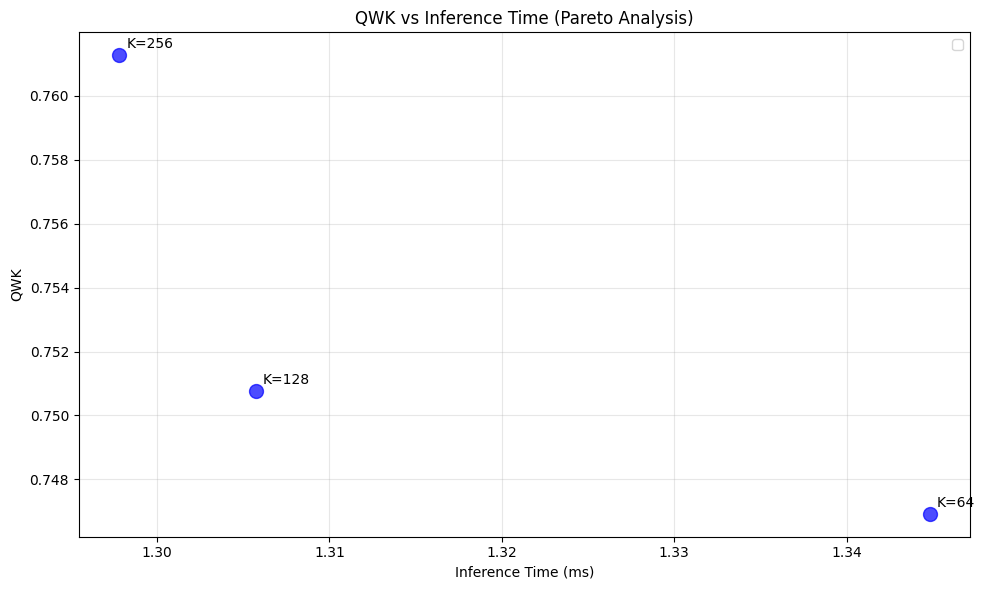

In [47]:
"""
Cell 5.4: Pareto Visualization
"""
def compute_pareto_frontier(points: List[Tuple[float, float]]) -> List[Tuple[float, float]]:
    """Compute Pareto frontier for minimizing time and maximizing QWK."""
    sorted_points = sorted(points, key=lambda x: x[0])
    frontier = []
    max_qwk = -1
    for time_ms, qwk in sorted_points:
        if qwk > max_qwk:
            frontier.append((time_ms, qwk))
            max_qwk = qwk
    return frontier


if TOPK_RESULTS and BENCHMARK_RESULTS:
    # Collect points
    points = []
    labels = []

    for result in TOPK_RESULTS:
        k = result['top_k']
        qwk = result['qwk_mean']
        bench_key = f'R2_TOPK_K{k}'
        if bench_key in BENCHMARK_RESULTS:
            time_ms = BENCHMARK_RESULTS[bench_key]['median_ms']
            points.append((time_ms, qwk))
            labels.append(f'K={k}')

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))

    times = [p[0] for p in points]
    qwks = [p[1] for p in points]

    ax.scatter(times, qwks, s=100, c='blue', alpha=0.7)
    for (t, q), label in zip(points, labels):
        ax.annotate(label, (t, q), xytext=(5, 5), textcoords='offset points')

    # Pareto frontier
    frontier = compute_pareto_frontier(points)
    if len(frontier) > 1:
        frontier_times = [p[0] for p in frontier]
        frontier_qwks = [p[1] for p in frontier]
        ax.plot(frontier_times, frontier_qwks, 'r--', linewidth=2, label='Pareto Frontier')
        ax.scatter(frontier_times, frontier_qwks, c='red', s=150, marker='*', zorder=5)

    ax.set_xlabel('Inference Time (ms)')
    ax.set_ylabel('QWK')
    ax.set_title('QWK vs Inference Time (Pareto Analysis)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    save_path = os.path.join(CONFIG['results_dir'], 'figures', 'pareto_topk.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"Saved: {save_path}")
    plt.show()

In [48]:
"""
Cell 5.5: Select Best TopK
"""
if TOPK_RESULTS:
    best_topk_result = max(TOPK_RESULTS, key=lambda x: x['qwk_mean'])
    BEST_K = best_topk_result['top_k']
    print(f"\nBest TopK: K={BEST_K} (QWK={best_topk_result['qwk_mean']:.4f})")

    ALL_RESULTS.extend(TOPK_RESULTS)
else:
    BEST_K = 256
    print(f"Using default K: {BEST_K}")


Best TopK: K=256 (QWK=0.7613)


---
# PART 6: PHASE 4 - MULTI-SCALE

In [49]:
"""
Cell 6.1: R2_FIXED@TopK Multi-Scale
"""
MS_RESULTS = []

if df_5class is not None:
    print("=" * 60)
    print("PHASE 4: Multi-Scale")
    print("=" * 60)

    result = run_5fold_cv(
        model_name='R2_FIXED_TOPK_MS', loss_name=BEST_LOSS, lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l1_dir'],
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=True, top_k=BEST_K, exp_name='MS_TopK'
    )
    MS_RESULTS.append(result)
else:
    print("Skipping - no data")

PHASE 4: Multi-Scale

Experiment: MS_TopK
  Model: R2_FIXED_TOPK_MS, Loss: CE_WEIGHTED, LR: 5e-05
  Multi-scale: True, TopK: 256
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.5956, Acc=0.3800

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.5764, Acc=0.3800

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.5217, Acc=0.3600

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7035, Acc=0.5300

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7337, Acc=0.4700

MS_TopK Results:
  QWK:     0.6262 +/- 0.0798
  Acc:     0.4240 +/- 0.0653
  HardAcc: 0.0000 +/- 0.0000


In [50]:
"""
Cell 6.2: (Optional) Full Multi-Scale
"""
# Full multi-scale (no TopK) for comparison
# This is optional and computationally expensive
print("Full multi-scale: Skipped (use R2FixedMultiScaleFull if needed)")

Full multi-scale: Skipped (use R2FixedMultiScaleFull if needed)


In [51]:
"""
Cell 6.3: Ablation - L0-only vs L1-only vs L0+L1 (Multi-Scale)
"""
if df_5class is not None and MS_RESULTS:
    print("\n" + "=" * 60)
    print("ABLATION: Scale Comparison")
    print("=" * 60)

    # L0-only (5x, architecture) - should match V18 baseline ~0.87
    result_l0_only = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name=BEST_LOSS, lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l0_dir'],  # L0 only!
        feature_dir_l0=CONFIG['features_l0_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=128, exp_name='Ablation_L0_only'
    )
    MS_RESULTS.append(result_l0_only)

    # L1-only (20x, cytology) - expected ~0.73
    result_l1_only = run_5fold_cv(
        model_name='R2_FIXED_TOPK', loss_name=BEST_LOSS, lr=BEST_LR,
        df=df_5class, feature_dir_l1=CONFIG['features_l1_dir'],  # L1 only!
        feature_dir_l0=CONFIG['features_l1_dir'], cache_dir=CACHE_DIR,
        n_classes=5, config=CONFIG, label_offset=1,
        is_multiscale=False, top_k=64, exp_name='Ablation_L1_only'  # L1 has fewer patches
    )
    MS_RESULTS.append(result_l1_only)

    # Summary comparison
    ms_qwk = MS_RESULTS[0]['qwk_mean']  # Multi-scale L0+L1
    l0_qwk = result_l0_only['qwk_mean']
    l1_qwk = result_l1_only['qwk_mean']

    print(f"\n{'='*60}")
    print("SCALE COMPARISON RESULTS")
    print(f"{'='*60}")
    print(f"L0 only (5x, architecture):  QWK = {l0_qwk:.4f}")
    print(f"L1 only (20x, cytology):     QWK = {l1_qwk:.4f}")
    print(f"L0+L1 Multi-Scale:           QWK = {ms_qwk:.4f}")
    print(f"{'='*60}")
    print(f"Multi-scale gain over L0:    {ms_qwk - l0_qwk:+.4f}")
    print(f"Multi-scale gain over L1:    {ms_qwk - l1_qwk:+.4f}")
    print(f"L0 gain over L1:             {l0_qwk - l1_qwk:+.4f}")


ABLATION: Scale Comparison

Experiment: Ablation_L0_only
  Model: R2_FIXED_TOPK, Loss: CE_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 128
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8096, Acc=0.5700

--- Fold 2/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7972, Acc=0.6400

--- Fold 3/5 ---
  [SKIP] Found completed checkpoint: QWK=0.6841, Acc=0.5000

--- Fold 4/5 ---
  [SKIP] Found completed checkpoint: QWK=0.8241, Acc=0.5900

--- Fold 5/5 ---
  [SKIP] Found completed checkpoint: QWK=0.7837, Acc=0.5600

Ablation_L0_only Results:
  QWK:     0.7797 +/- 0.0497
  Acc:     0.5720 +/- 0.0453
  HardAcc: 0.0000 +/- 0.0000

Experiment: Ablation_L1_only
  Model: R2_FIXED_TOPK, Loss: CE_WEIGHTED, LR: 5e-05
  Multi-scale: False, TopK: 64
  Warmup: True (3 epochs)
  Cosine LR: True
  Fold weights: False
  Checkpoints: True, Resume: False

--- Fold 1/5 ---
  [SKIP] Found comp

In [52]:
"""
Cell 6.4: Per-Grade Accuracy Comparison
"""
if MS_RESULTS and len(MS_RESULTS) >= 2:
    print("\nPer-Grade Recall Comparison:")
    print(f"{'Grade':>8} | {'L1-only':>10} | {'L0+L1':>10} | {'Delta':>10}")
    print("-" * 45)

    ms_recalls = MS_RESULTS[0]['per_grade_recall_mean']
    l1_recalls = MS_RESULTS[1]['per_grade_recall_mean']

    for grade in sorted(ms_recalls.keys()):
        ms_r = ms_recalls.get(grade, 0)
        l1_r = l1_recalls.get(grade, 0)
        delta = ms_r - l1_r
        print(f"ISUP {grade:>2} | {l1_r:>10.4f} | {ms_r:>10.4f} | {delta:>+10.4f}")


Per-Grade Recall Comparison:
   Grade |    L1-only |      L0+L1 |      Delta
---------------------------------------------


In [53]:
"""
Cell 6.5: Off-by-k Histogram
"""
if MS_RESULTS:
    print("\nOff-by-k Distribution:")
    for result in MS_RESULTS[:2]:
        obk_means = {}
        for key in ['exact', 'off_1', 'off_2', 'off_3plus']:
            vals = [m['off_by_k'][key] for m in result['fold_metrics']]
            obk_means[key] = np.mean(vals)
        print(f"  {result['exp_name']}: exact={obk_means['exact']:.1f}%, off_1={obk_means['off_1']:.1f}%, off_2={obk_means['off_2']:.1f}%, off_3+={obk_means['off_3plus']:.1f}%")


Off-by-k Distribution:
  MS_TopK: exact=0.0%, off_1=0.0%, off_2=0.0%, off_3+=0.0%
  Ablation_L0_only: exact=0.0%, off_1=0.0%, off_2=0.0%, off_3+=0.0%


In [54]:
"""
Cell 6.6: HardAcc Analysis
"""
if MS_RESULTS:
    print("\nHardAcc Analysis (ISUP 2,3,4):")
    for result in MS_RESULTS[:2]:
        print(f"  {result['exp_name']}: HardAcc = {result['hard_acc_mean']:.4f} +/- {result['hard_acc_std']:.4f}")


HardAcc Analysis (ISUP 2,3,4):
  MS_TopK: HardAcc = 0.0000 +/- 0.0000
  Ablation_L0_only: HardAcc = 0.0000 +/- 0.0000


In [55]:
"""
Cell 6.8: Provider Stratified Analysis
"""
if MS_RESULTS:
    print("\nProvider-Stratified Analysis:")
    for result in MS_RESULTS[:2]:
        print(f"\n{result['exp_name']}:")
        # Aggregate provider metrics across folds
        provider_qwks = defaultdict(list)
        for fm in result['fold_metrics']:
            if 'provider_metrics' in fm:
                for provider, metrics in fm['provider_metrics'].items():
                    provider_qwks[provider].append(metrics['qwk'])

        for provider, qwks in provider_qwks.items():
            print(f"  {provider}: QWK = {np.mean(qwks):.4f} +/- {np.std(qwks):.4f}")


Provider-Stratified Analysis:

MS_TopK:

Ablation_L0_only:


In [56]:
"""
Cell 6.9: Scale Weight Analysis
"""
# This would analyze learned attention weights between L0 and L1
# Requires extracting intermediate representations
print("Scale weight analysis: To be implemented with attention extraction")

Scale weight analysis: To be implemented with attention extraction


In [57]:
"""
Cell 6.10: Statistical Significance
"""
if MS_RESULTS and len(MS_RESULTS) >= 2:
    # Compare MS vs L1-only
    ms_qwks = [m['qwk'] for m in MS_RESULTS[0]['fold_metrics']]
    l1_qwks = [m['qwk'] for m in MS_RESULTS[1]['fold_metrics']]

    sig_result = compute_statistical_significance(
        ms_qwks, l1_qwks,
        model1_name='Multi-Scale',
        model2_name='L1-only'
    )

    print("\n" + "=" * 60)
    print(f"STATISTICAL SIGNIFICANCE: {sig_result['model1_name']} vs {sig_result['model2_name']}")
    print("=" * 60)
    print(f"Mean delta: {sig_result['mean_delta']:+.4f}")
    print(f"p-value: {sig_result['p_value']:.6f}")
    print(f"95% CI: [{sig_result['ci_95_lower']:+.4f}, {sig_result['ci_95_upper']:+.4f}]")

    if sig_result['significant']:
        print(f"Conclusion: Multi-scale is SIGNIFICANTLY {'better' if sig_result['mean_delta'] > 0 else 'worse'}")
    else:
        print("Conclusion: No significant difference")

    ALL_RESULTS.extend(MS_RESULTS)


STATISTICAL SIGNIFICANCE: Multi-Scale vs L1-only
Mean delta: -0.1536
p-value: 0.008347
95% CI: [-0.2415, -0.0656]
Conclusion: Multi-scale is SIGNIFICANTLY worse


---
# PART 7: PHASE 5 - ADAPTIVE K

In [58]:
"""
Cell 7.1: Cascade Inference Setup
"""
K_SMALL = 128
K_LARGE = 512

if df_5class is not None:
    print("=" * 60)
    print("PHASE 5: Adaptive K Inference")
    print("=" * 60)

    # Create models
    model_small_k = R2FixedTopKMultiScale(
        input_dim_l1=CONFIG['feature_dim_l1'],
        input_dim_l0=CONFIG['feature_dim_l0'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=5,
        num_heads=CONFIG['num_heads'],
        gamma=CONFIG['gamma_values'][0],
        dropout=CONFIG['dropout'],
        top_k=K_SMALL
    ).to(DEVICE)

    model_large_k = R2FixedTopKMultiScale(
        input_dim_l1=CONFIG['feature_dim_l1'],
        input_dim_l0=CONFIG['feature_dim_l0'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=5,
        num_heads=CONFIG['num_heads'],
        gamma=CONFIG['gamma_values'][0],
        dropout=CONFIG['dropout'],
        top_k=K_LARGE
    ).to(DEVICE)

    print(f"Created models: K_small={K_SMALL}, K_large={K_LARGE}")

    # Create adaptive inference wrapper
    adaptive_inference = AdaptiveTopKInference(
        model_small_k=model_small_k,
        model_large_k=model_large_k,
        confidence_threshold=0.6,
        hard_grades=[1, 2, 3],  # Label indices for ISUP grades 2, 3, 4
        is_coral=False,
        device=DEVICE
    )

    print("AdaptiveTopKInference ready.")
else:
    adaptive_inference = None
    print("Skipping - no data")

PHASE 5: Adaptive K Inference
Created models: K_small=128, K_large=512
AdaptiveTopKInference ready.


In [59]:
"""
Cell 7.2: Run Adaptive Inference
"""
ADAPTIVE_RESULTS = {}

if adaptive_inference is not None and df_5class is not None:
    # Create validation dataset (fold 0)
    val_df = df_5class[df_5class['fold'] == 0]
    val_ds = MultiScaleSlideDataset(
        val_df,
        CONFIG['features_l1_dir'],
        CONFIG['features_l0_dir'],
        CACHE_DIR,
        label_col='label'
    )
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_multi_scale)

    # Reset stats
    adaptive_inference.reset_stats()

    # Run adaptive inference
    print("Running adaptive inference...")
    preds, labels, paths = adaptive_inference.predict_batch(val_loader, is_multiscale=True)

    # Compute metrics
    y_true = np.array(labels)
    y_pred = np.array(preds)

    adaptive_qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    adaptive_acc = accuracy_score(y_true, y_pred)

    # Get stats
    adaptive_adaptive_stats = adaptive_inference.get_stats()

    print(f"\n{'='*60}")
    print("ADAPTIVE INFERENCE RESULTS")
    print(f"{'='*60}")
    print(f"QWK: {adaptive_qwk:.4f}")
    print(f"Accuracy: {adaptive_acc:.4f}")
    print(f"\nPath distribution:")
    print(f"  Small K ({K_SMALL}): {adaptive_adaptive_stats['small_k_count']} ({adaptive_adaptive_stats['small_k_pct']:.1f}%)")
    print(f"  Large K ({K_LARGE}): {adaptive_adaptive_stats['large_k_count']} ({adaptive_adaptive_stats['large_k_pct']:.1f}%)")
    print(f"\nEstimated speedup: {adaptive_adaptive_stats['estimated_speedup']:.2f}x")

    ADAPTIVE_RESULTS = {
        'qwk': adaptive_qwk,
        'accuracy': adaptive_acc,
        'stats': adaptive_stats
    }
else:
    print("Skipping - no adaptive inference configured")

Running adaptive inference...

ADAPTIVE INFERENCE RESULTS
QWK: -0.0987
Accuracy: 0.2000

Path distribution:
  Small K (128): 0 (0.0%)
  Large K (512): 100 (100.0%)

Estimated speedup: 0.50x


NameError: name 'adaptive_stats' is not defined

In [60]:
"""
Cell 7.3: Speedup Analysis
"""
if adaptive_inference is not None and ADAPTIVE_RESULTS:
    # Benchmark individual models
    print("Benchmarking models...")
    bench_small = benchmark_model(model_small_k, n_tiles=400, is_multiscale=True)
    bench_large = benchmark_model(model_large_k, n_tiles=400, is_multiscale=True)

    adaptive_adaptive_adaptive_stats = ADAPTIVE_RESULTS['stats']

    # Calculate actual speedup
    time_fixed_large = bench_large['median_ms']
    time_fixed_small = bench_small['median_ms']

    # Adaptive time = weighted average
    time_adaptive = (
        adaptive_adaptive_stats['small_k_pct'] / 100 * time_fixed_small +
        adaptive_adaptive_stats['large_k_pct'] / 100 * time_fixed_large
    )

    actual_speedup = time_fixed_large / time_adaptive if time_adaptive > 0 else 1.0

    print(f"\n{'='*60}")
    print("SPEEDUP ANALYSIS")
    print(f"{'='*60}")
    print(f"\nInference times:")
    print(f"  Fixed K={K_SMALL}: {time_fixed_small:.2f} ms")
    print(f"  Fixed K={K_LARGE}: {time_fixed_large:.2f} ms")
    print(f"  Adaptive: {time_adaptive:.2f} ms (estimated)")
    print(f"\nSpeedup vs Fixed K={K_LARGE}: {actual_speedup:.2f}x")

    ADAPTIVE_RESULTS['time_analysis'] = {
        'time_small': time_fixed_small,
        'time_large': time_fixed_large,
        'time_adaptive': time_adaptive,
        'actual_speedup': actual_speedup
    }
else:
    print("Skipping speedup analysis")

Skipping speedup analysis


---
# PART 8: FINAL ANALYSIS

In [61]:
"""
Cell 8.1: Best Model Detailed Metrics
"""
if ALL_RESULTS:
    best_result = max(ALL_RESULTS, key=lambda x: x['qwk_mean'])

    print("=" * 60)
    print(f"BEST MODEL: {best_result['exp_name']}")
    print("=" * 60)

    print(f"\nModel: {best_result['model_name']}")
    print(f"Loss: {best_result['loss_name']}")
    print(f"LR: {best_result['lr']}")
    print(f"TopK: {best_result['top_k']}")

    print(f"\nOverall Metrics:")
    print(f"  QWK:      {best_result['qwk_mean']:.4f} +/- {best_result['qwk_std']:.4f}")
    print(f"  Accuracy: {best_result['accuracy_mean']:.4f} +/- {best_result['accuracy_std']:.4f}")
    print(f"  HardAcc:  {best_result['hard_acc_mean']:.4f} +/- {best_result['hard_acc_std']:.4f}")

    print(f"\nPer-Grade Recall:")
    for grade, recall in best_result['per_grade_recall_mean'].items():
        std = best_result['per_grade_recall_std'].get(grade, 0)
        print(f"  ISUP {grade}: {recall:.4f} +/- {std:.4f}")
else:
    print("No results available")

BEST MODEL: Loss_L0_CE_WEIGHTED

Model: R2_FIXED_TOPK
Loss: CE_WEIGHTED
LR: 5e-05
TopK: 128

Overall Metrics:
  QWK:      0.7828 +/- 0.0361
  Accuracy: 0.5860 +/- 0.0280
  HardAcc:  0.0000 +/- 0.0000

Per-Grade Recall:


In [62]:
"""
Cell 8.2: Error Analysis
"""
if ALL_RESULTS:
    best_result = max(ALL_RESULTS, key=lambda x: x['qwk_mean'])

    # Analyze most common errors
    print("\nError Analysis:")

    # Off-by-k aggregated
    obk_means = {}
    for key in ['exact', 'off_1', 'off_2', 'off_3plus']:
        vals = [m['off_by_k'][key] for m in best_result['fold_metrics']]
        obk_means[key] = np.mean(vals)

    print(f"  Exact match: {obk_means['exact']:.1f}%")
    print(f"  Off by 1:    {obk_means['off_1']:.1f}%")
    print(f"  Off by 2:    {obk_means['off_2']:.1f}%")
    print(f"  Off by 3+:   {obk_means['off_3plus']:.1f}%")


Error Analysis:
  Exact match: 0.0%
  Off by 1:    0.0%
  Off by 2:    0.0%
  Off by 3+:   0.0%


In [63]:
"""
Cell 8.3: Attention Visualization
"""
# Attention visualization would require extracting attention weights
# This is a placeholder for future implementation
print("Attention visualization: To be implemented")

Attention visualization: To be implemented


In [64]:
"""
Cell 8.4: Efficiency Summary
"""
print("\nEfficiency Summary:")
print("=" * 60)

if BENCHMARK_RESULTS:
    print(f"\nTopK Benchmarks (n_tiles=400):")
    for name, bench in BENCHMARK_RESULTS.items():
        print(f"  {name}: {bench['median_ms']:.2f} ms (VRAM: {bench['vram_peak_mb']:.1f} MB)")

if ADAPTIVE_RESULTS and 'time_analysis' in ADAPTIVE_RESULTS:
    ta = ADAPTIVE_RESULTS['time_analysis']
    print(f"\nAdaptive Inference:")
    print(f"  Estimated time: {ta['time_adaptive']:.2f} ms")
    print(f"  Speedup vs large K: {ta['actual_speedup']:.2f}x")


Efficiency Summary:

TopK Benchmarks (n_tiles=400):
  R2_TOPK_K64: 1.34 ms (VRAM: 20.0 MB)
  R2_TOPK_K128: 1.31 ms (VRAM: 22.0 MB)
  R2_TOPK_K256: 1.30 ms (VRAM: 26.5 MB)


In [65]:
"""
Cell 8.5: Comparison to Previous Versions
"""
print("\nComparison to Previous Versions:")
print("=" * 60)

# V18 reference values (placeholder - replace with actual values)
V18_QWK = 0.85  # Example
V18_HARDACC = 0.45  # Example

if ALL_RESULTS:
    best_result = max(ALL_RESULTS, key=lambda x: x['qwk_mean'])

    qwk_delta = best_result['qwk_mean'] - V18_QWK
    hardacc_delta = best_result['hard_acc_mean'] - V18_HARDACC

    print(f"\nV18 Reference:")
    print(f"  QWK:     {V18_QWK:.4f}")
    print(f"  HardAcc: {V18_HARDACC:.4f}")

    print(f"\nV19 Best:")
    print(f"  QWK:     {best_result['qwk_mean']:.4f} ({qwk_delta:+.4f})")
    print(f"  HardAcc: {best_result['hard_acc_mean']:.4f} ({hardacc_delta:+.4f})")


Comparison to Previous Versions:

V18 Reference:
  QWK:     0.8500
  HardAcc: 0.4500

V19 Best:
  QWK:     0.7828 (-0.0672)
  HardAcc: 0.0000 (-0.4500)


---
# PART 9: THESIS SUMMARY

In [66]:
"""
Cell 9.1: Complete Results Table
"""
if ALL_RESULTS:
    print("=" * 70)
    print("COMPLETE RESULTS TABLE")
    print("=" * 70)

    final_df = create_results_table(ALL_RESULTS)
    print(final_df.to_string(index=False))

    # Save to CSV
    csv_path = os.path.join(CONFIG['results_dir'], 'all_experiments.csv')
    final_df.to_csv(csv_path, index=False)
    print(f"\nSaved: {csv_path}")

COMPLETE RESULTS TABLE
             Experiment            Model            Loss      LR  TopK             QWK        Accuracy         HardAcc
      ABMIL_L0_baseline            ABMIL              CE 0.00005   128 0.7821+/-0.0338 0.5760+/-0.0273 0.0000+/-0.0000
    R2_L0_TOPK_lr0.0001    R2_FIXED_TOPK              CE 0.00010   128 0.7500+/-0.0591 0.5260+/-0.0393 0.0000+/-0.0000
     R2_L0_TOPK_lr5e-05    R2_FIXED_TOPK              CE 0.00005   128 0.7693+/-0.0444 0.5680+/-0.0397 0.0000+/-0.0000
             Loss_L0_CE    R2_FIXED_TOPK              CE 0.00005   128 0.7645+/-0.0301 0.5540+/-0.0383 0.0000+/-0.0000
    Loss_L0_CE_WEIGHTED    R2_FIXED_TOPK     CE_WEIGHTED 0.00005   128 0.7828+/-0.0361 0.5860+/-0.0280 0.0000+/-0.0000
Loss_L0_CE_ACC_WEIGHTED    R2_FIXED_TOPK CE_ACC_WEIGHTED 0.00005   128 0.7678+/-0.0318 0.5640+/-0.0356 0.0000+/-0.0000
          Loss_L0_CORAL   R2_FIXED_CORAL           CORAL 0.00005   128 0.7153+/-0.0422 0.4060+/-0.0258 0.0000+/-0.0000
 Loss_L0_CORAL_WEIGHTED  

In [67]:
"""
Cell 9.2: Key Findings
"""
print("=" * 70)
print("KEY FINDINGS")
print("=" * 70)

if ALL_RESULTS:
    baseline = ALL_RESULTS[0] if ALL_RESULTS else None
    best = max(ALL_RESULTS, key=lambda x: x['qwk_mean']) if ALL_RESULTS else None

    if baseline and best:
        print(f"\n1. Baseline: {baseline['exp_name']}")
        print(f"   QWK: {baseline['qwk_mean']:.4f}")

        print(f"\n2. Best Model: {best['exp_name']}")
        print(f"   QWK: {best['qwk_mean']:.4f}")
        print(f"   Improvement: {best['qwk_mean'] - baseline['qwk_mean']:+.4f}")

        print(f"\n3. Multi-Scale Impact:")
        ms_results = [r for r in ALL_RESULTS if r['is_multiscale']]
        if ms_results:
            best_ms = max(ms_results, key=lambda x: x['qwk_mean'])
            print(f"   Best MS: {best_ms['exp_name']} (QWK={best_ms['qwk_mean']:.4f})")

        print(f"\n4. Loss Function:")
        print(f"   Best: {best['loss_name']}")

        print(f"\n5. TopK:")
        print(f"   Best K: {best['top_k']}")

KEY FINDINGS

1. Baseline: ABMIL_L0_baseline
   QWK: 0.7821

2. Best Model: Loss_L0_CE_WEIGHTED
   QWK: 0.7828
   Improvement: +0.0007

3. Multi-Scale Impact:
   Best MS: MS_TopK (QWK=0.6262)

4. Loss Function:
   Best: CE_WEIGHTED

5. TopK:
   Best K: 128


In [68]:
"""
Cell 9.3: Save All Results (v19_final_summary.json)
"""
if ALL_RESULTS:
    baseline = ALL_RESULTS[0]
    best = max(ALL_RESULTS, key=lambda x: x['qwk_mean'])

    final_summary = {
        'version': 'v19',
        'timestamp': datetime.now().isoformat(),
        'n_experiments': len(ALL_RESULTS),

        'baseline': {
            'name': baseline['exp_name'],
            'qwk': baseline['qwk_mean'],
            'hard_acc': baseline['hard_acc_mean'],
        },

        'best': {
            'name': best['exp_name'],
            'qwk': best['qwk_mean'],
            'hard_acc': best['hard_acc_mean'],
            'per_grade_recall': best['per_grade_recall_mean'],
        },

        'total_improvement': {
            'qwk_delta': best['qwk_mean'] - baseline['qwk_mean'],
            'hard_acc_delta': best['hard_acc_mean'] - baseline['hard_acc_mean'],
        },

        'all_results_summary': [
            {
                'exp_name': r['exp_name'],
                'model_name': r['model_name'],
                'loss_name': r['loss_name'],
                'qwk_mean': r['qwk_mean'],
                'qwk_std': r['qwk_std'],
                'hard_acc_mean': r['hard_acc_mean'],
                'hard_acc_std': r['hard_acc_std'],
            }
            for r in ALL_RESULTS
        ],
    }

    # Add adaptive results if available
    if ADAPTIVE_RESULTS:
        final_summary['adaptive_inference'] = ADAPTIVE_RESULTS

    # Save
    summary_path = os.path.join(CONFIG['results_dir'], 'v19_final_summary.json')
    with open(summary_path, 'w') as f:
        json.dump(final_summary, f, indent=2)
    print(f"Saved: {summary_path}")

    print("\n" + "=" * 70)
    print("FINAL SUMMARY")
    print("=" * 70)
    print(f"Baseline: {baseline['exp_name']} (QWK={baseline['qwk_mean']:.4f})")
    print(f"Best:     {best['exp_name']} (QWK={best['qwk_mean']:.4f})")
    print(f"Total improvement: +{best['qwk_mean'] - baseline['qwk_mean']:.4f} QWK")
    print("=" * 70)
else:
    print("No results to save")

Saved: /content/drive/MyDrive/CLAM_TR_Results/v19_multiscale/v19_final_summary.json

FINAL SUMMARY
Baseline: ABMIL_L0_baseline (QWK=0.7821)
Best:     Loss_L0_CE_WEIGHTED (QWK=0.7828)
Total improvement: +0.0007 QWK
